### Ô 1: Khởi tạo môi trường, Kết nối Google Drive và Đồng bộ Repository
- **Mục đích:** Tải mã nguồn cùng kết quả đầu ra của Module 1, Module 2 từ nhánh `main` (`https://github.com/haleduoc/MRI.git`), kết nối thư mục lưu trữ kết quả trên Google Drive (`MRI_Colab_Results`) và kiểm tra bộ dữ liệu NIfTI BraTS2020 đã chuẩn hóa hướng RAS.
- **Đầu vào:** Kho mã nguồn Git của nhóm và các file `chi_muc_lat.csv`, `phan_chia_benh_nhan.csv` từ Module 2.
- **Đầu ra:** Môi trường làm việc tại `/content/MRI` sẵn sàng cho thực nghiệm Module 3 và Module 4.

In [ ]:
!git clone https://github.com/haleduoc/MRI.git
%cd MRI
!git branch -a
!find . -maxdepth 3 -not -path '*/.*'

Cloning into 'MRI'...
remote: Enumerating objects: 475, done.
remote: Counting objects: 100% (475/475), done.
remote: Compressing objects: 100% (459/459), done.
remote: Total 475 (delta 16), reused 455 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (475/475), 29.61 MiB | 23.56 MiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/MRI
* main
  remotes/origin/HEAD -> origin/main
  remotes/origin/feature/evaluation
  remotes/origin/feature/interface
  remotes/origin/feature/preprocessing
  remotes/origin/feature/segmentation
  remotes/origin/main
.
./docs
./docs/MRI.pdf
./docs/MRI.drawio
./docs/MRI (1).drawio
./requirements.txt
./notebooks
./notebooks/pipeline.ipynb
./modules
./modules/module 1
./modules/module 1/04: Chuẩn bị nhãn lát.py
./modules/module 1/01: Kiểm kê dataset.py
./modules/module 1/03: Chuẩn hóa hướng ảnh.py
./modules/module 1/05: Kiểm tra và thống kê.py
./modules/module 1/02: Kiểm tra cặp FLAIR Segmentation.py
./modules/module 2
./modules/module 2/02: Lập

In [ ]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation")
print("Đường dẫn chứa dataset trên Colab:", dataset_path)
print("Các thư mục bên trong:", os.listdir(dataset_path))

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Đường dẫn chứa dataset trên Colab: /kaggle/input/brats20-dataset-training-validation
Các thư mục bên trong: ['BraTS2020_ValidationData', 'BraTS2020_TrainingData']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Tạo thư mục liên kết trực tiếp từ Colab sang Google Drive của em
!mkdir -p "/content/drive/MyDrive/MRI_Colab_Results"
!cp -r ./results/module3_step_by_step/* "/content/drive/MyDrive/MRI_Colab_Results/"

Mounted at /content/drive


# Khối 1 — Bước 0 (Lấy 5 mẫu gốc sau Module 2):
# PHẦN 1: THỰC NGHIỆM TỪNG BƯỚC TRÊN 5 MẪU THỬ ĐẠI DIỆN VÀ ĐÚC KẾT THAM SỐ CHUẨN
### Bước 0: Nạp dữ liệu đầu ra từ Module 1 & 2 và Khảo sát thông số vật lý gốc trên 5 lát cắt đại diện
- **Đầu vào kế thừa từ Module 1 & 2:**
  - Khối ảnh 3D NIfTI đã chuẩn hóa hướng RAS (`240 × 240 × 155`) và mặt nạ nhị phân `WT` (gộp nhãn `{1, 2, 4}`).
  - Bảng chỉ mục lát cắt `results/module2/Chi_muc_lat/chi_muc_lat.csv` (`57.040` lát cắt từ `368` bệnh nhân hợp lệ).
- **Mục đích Bước 0:** Trích xuất 5 lát cắt đại diện từ tập huấn luyện `R` (Mẫu 1: U lớn `001 z=78`; Mẫu 2: U nhỏ/rìa u có nhiễu cực đại `002 z=50`; Mẫu 3: U bờ mờ `003 z=85`; Mẫu 4: Lát mô não lành không u `005 z=75`; Mẫu 5: Lát rỗng vùng đỉnh sọ `001 z=2`) để đo đạc các thông số vật lý ban đầu trước khi qua Module 3: diện tích vùng não $A_{\text{brain}} = \sum \mathbb{I}(I > 0)$, diện tích vùng u $|WT|$, $[I_{\min}, I_{\max}]$, phân vị vùng não $[P_1, P_{99}]$, mức xám trung bình mô lành $\mu_0$ và vùng u $\mu_1$.

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Tổng số dòng trong chi_muc_lat.csv (Đầu ra Module 2): 57040

=== THÔNG SỐ GỐC CỦA 5 LÁT CẮT SAU MODULE 1 & 2 (INPUT CỦA MODULE 3) ===
  Mẫu           Patient_ID  Slice_z Split (M2)  Label (M2)      Shape  Số pixel não (I>0)  Số pixel u (WT=1)  I_min  I_max  P1 (Não)  P99 (Não)  TB Mô lành  TB Vùng u
Mẫu 1 BraTS20_Training_001       78          R           1 (240, 240)               17424               4453    0.0  432.0      43.0      383.0       148.3      296.2
Mẫu 2 BraTS20_Training_002       50          R           1 (240, 240)               16379               2019    0.0 1091.0     101.0      720.2       312.1      555.2
Mẫu 3 BraTS20_Training_003       85          R           1 (240, 240)               15815                748    0.0  553.0      68.0      493.0       307.1      462.6
Mẫu 4 BraTS20_Training_005       75          R           0 (240, 240)               17154                  0

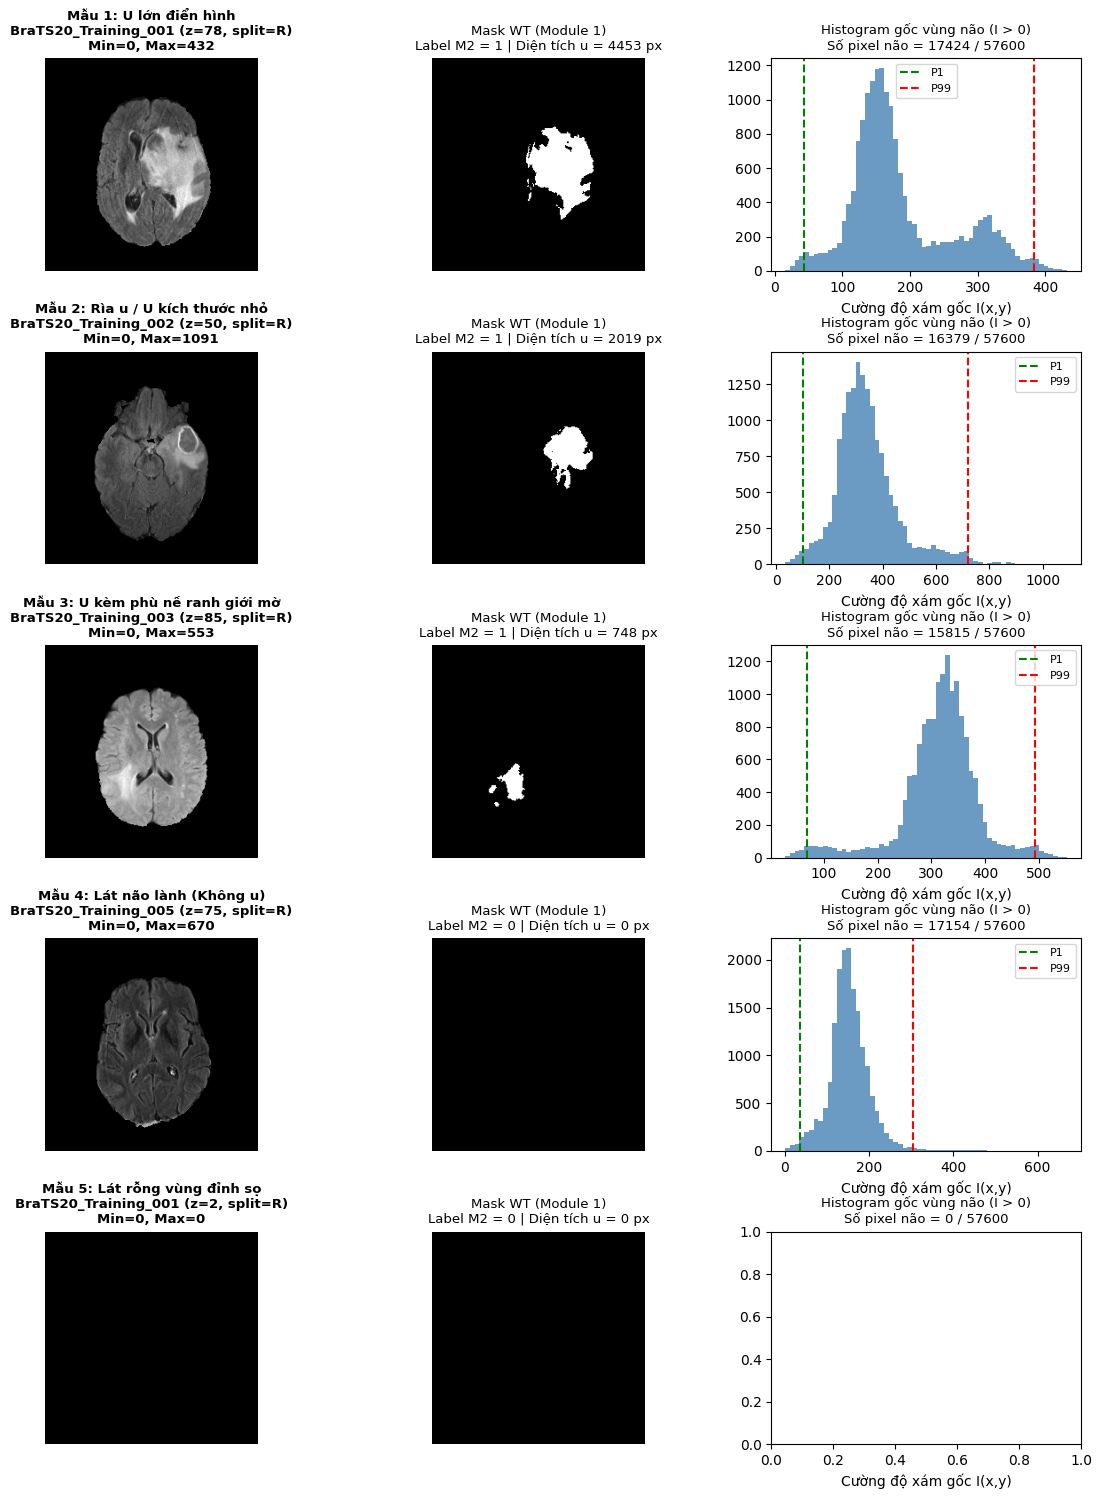

In [4]:
# ==============================================================================
# BƯỚC 0: TRÍCH XUẤT 5 LÁT CẮT ĐẠI DIỆN SAU MODULE 1 & 2 VÀ ĐO THÔNG SỐ GỐC
# ==============================================================================
import os, zipfile, glob, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import kagglehub
from google.colab import drive

if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

repo_root = Path("/content/MRI")
if not repo_root.exists():
    subprocess.run(["git", "clone", "https://github.com/haleduoc/MRI.git", "/content/MRI"], check=True)
os.chdir(repo_root)

drive_out = "/content/drive/MyDrive/MRI_Colab_Results"
os.makedirs(drive_out, exist_ok=True)
kaggle_root = Path(kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation"))

df_index = pd.read_csv("./results/module2/Chi_muc_lat/chi_muc_lat.csv")
print("Tổng số dòng trong chi_muc_lat.csv (Đầu ra Module 2):", len(df_index))

extract_dir = Path("/content/nifti_ras_all368")
extract_dir.mkdir(parents=True, exist_ok=True)
zip_files = glob.glob("./results/module1/**/nifti_outputs.zip", recursive=True)

def load_ras_volume(pid):
    for folder in ["./results/module1/Kết_quả_chuẩn_hoá_RAS/nifti", "./results/module1/Kết quả chuẩn hóa RAS/nifti"]:
        f_p = os.path.join(folder, pid, f"{pid}_flair_RAS.nii.gz")
        w_p = os.path.join(folder, pid, f"{pid}_wt_RAS.nii.gz")
        if os.path.exists(f_p) and os.path.exists(w_p):
            return nib.load(f_p).get_fdata().astype(np.float32), nib.load(w_p).get_fdata().astype(np.uint8)
    f_m = list(extract_dir.rglob(f"*{pid}*flair*.nii*"))
    w_m = list(extract_dir.rglob(f"*{pid}*wt*.nii*"))
    if f_m and w_m:
        return nib.load(str(f_m[0])).get_fdata().astype(np.float32), nib.load(str(w_m[0])).get_fdata().astype(np.uint8)
    k_sub = f"BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/{pid}"
    k_dir = kaggle_root / k_sub
    f_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_flair.nii")))
    s_nii = nib.as_closest_canonical(nib.load(str(k_dir / f"{pid}_seg.nii")))
    wt_arr = np.isin(s_nii.get_fdata(), [1, 2, 4]).astype(np.uint8)
    return f_nii.get_fdata().astype(np.float32), wt_arr

selected_targets = [
    ("BraTS20_Training_001", 78, "Mẫu 1: U lớn điển hình"),
    ("BraTS20_Training_002", 50, "Mẫu 2: Rìa u / U kích thước nhỏ"),
    ("BraTS20_Training_003", 85, "Mẫu 3: U kèm phù nề ranh giới mờ"),
    ("BraTS20_Training_005", 75, "Mẫu 4: Lát não lành (Không u)"),
    ("BraTS20_Training_001", 2,  "Mẫu 5: Lát rỗng vùng đỉnh sọ"),
]

samples_step0 = []
stats_rows = []

for pid, z_idx, note in selected_targets:
    row_m2 = df_index[(df_index["patient_id"] == pid) & (df_index["slice_index"] == z_idx)].iloc[0]
    flair_vol, wt_vol = load_ras_volume(pid)
    flair_slice = flair_vol[:, :, z_idx]
    wt_slice = wt_vol[:, :, z_idx]

    brain_pixels = flair_slice[flair_slice > 0]
    tumor_pixels = flair_slice[wt_slice > 0]
    healthy_pixels = flair_slice[(flair_slice > 0) & (wt_slice == 0)]

    samples_step0.append({
        "pid": pid, "z": z_idx, "split": row_m2["split"], "label": int(row_m2["label"]),
        "note": note, "flair": flair_slice, "wt": wt_slice,
    })

    stats_rows.append({
        "Mẫu": note.split(":")[0],
        "Patient_ID": pid,
        "Slice_z": z_idx,
        "Split (M2)": row_m2["split"],
        "Label (M2)": int(row_m2["label"]),
        "Shape": str(flair_slice.shape),
        "Số pixel não (I>0)": int((flair_slice > 0).sum()),
        "Số pixel u (WT=1)": int((wt_slice > 0).sum()),
        "I_min": round(float(flair_slice.min()), 1),
        "I_max": round(float(flair_slice.max()), 1),
        "P1 (Não)": round(float(np.percentile(brain_pixels, 1)), 1) if len(brain_pixels) > 0 else 0.0,
        "P99 (Não)": round(float(np.percentile(brain_pixels, 99)), 1) if len(brain_pixels) > 0 else 0.0,
        "TB Mô lành": round(float(healthy_pixels.mean()), 1) if len(healthy_pixels) > 0 else 0.0,
        "TB Vùng u": round(float(tumor_pixels.mean()), 1) if len(tumor_pixels) > 0 else 0.0,
    })

df_step0 = pd.DataFrame(stats_rows)
print("\n=== THÔNG SỐ GỐC CỦA 5 LÁT CẮT SAU MODULE 1 & 2 (INPUT CỦA MODULE 3) ===")
print(df_step0.to_string(index=False))

fig, axes = plt.subplots(5, 3, figsize=(14, 18))
plt.subplots_adjust(wspace=0.25, hspace=0.38)
for i, s in enumerate(samples_step0):
    axes[i, 0].imshow(np.rot90(s["flair"]), cmap="gray")
    axes[i, 0].set_title(f"{s['note']}\n{s['pid']} (z={s['z']}, split={s['split']})\nMin={s['flair'].min():.0f}, Max={s['flair'].max():.0f}", fontsize=9.5, fontweight="bold")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(np.rot90(s["wt"]), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Mask WT (Module 1)\nLabel M2 = {s['label']} | Diện tích u = {(s['wt']>0).sum()} px", fontsize=9.5)
    axes[i, 1].axis("off")

    bp = s["flair"][s["flair"] > 0]
    if len(bp) > 0:
        axes[i, 2].hist(bp.ravel(), bins=60, color="steelblue", alpha=0.8)
        axes[i, 2].axvline(np.percentile(bp, 1), color="green", linestyle="--", label="P1")
        axes[i, 2].axvline(np.percentile(bp, 99), color="red", linestyle="--", label="P99")
        axes[i, 2].legend(fontsize=8)
    axes[i, 2].set_title(f"Histogram gốc vùng não (I > 0)\nSố pixel não = {len(bp)} / 57600", fontsize=9.5)
    axes[i, 2].set_xlabel("Cường độ xám gốc I(x,y)")

plt.savefig(os.path.join(drive_out, "Step0_Raw_5Samples_Input.png"), dpi=300, bbox_inches="tight")
plt.show()

# Khối 2 — Bước 1 (Lọc lát rỗng & Chuẩn hóa cường độ):
### Bước 1 (Module 3): Lọc lát rỗng theo FLAIR & Đối chứng Chuẩn hóa Min-Max vs Percentile Clipping

=== 1A. KIỂM TRA LỌC LÁT RỖNG (BRAIN FOREGROUND FILTERING) ===
- Mẫu 1: U lớn điển hình (BraTS20_Training_001, z=78): Số pixel não = 17424 (30.25%) -> GIỮ LẠI (Hợp lệ)
- Mẫu 2: Rìa u / U kích thước nhỏ (BraTS20_Training_002, z=50): Số pixel não = 16379 (28.44%) -> GIỮ LẠI (Hợp lệ)
- Mẫu 3: U kèm phù nề ranh giới mờ (BraTS20_Training_003, z=85): Số pixel não = 15815 (27.46%) -> GIỮ LẠI (Hợp lệ)
- Mẫu 4: Lát não lành (Không u) (BraTS20_Training_005, z=75): Số pixel não = 17154 (29.78%) -> GIỮ LẠI (Hợp lệ)
- Mẫu 5: Lát rỗng vùng đỉnh sọ (BraTS20_Training_001, z=2): Số pixel não = 0 (0.00%) -> LOẠI BỎ (Lát rỗng không não)


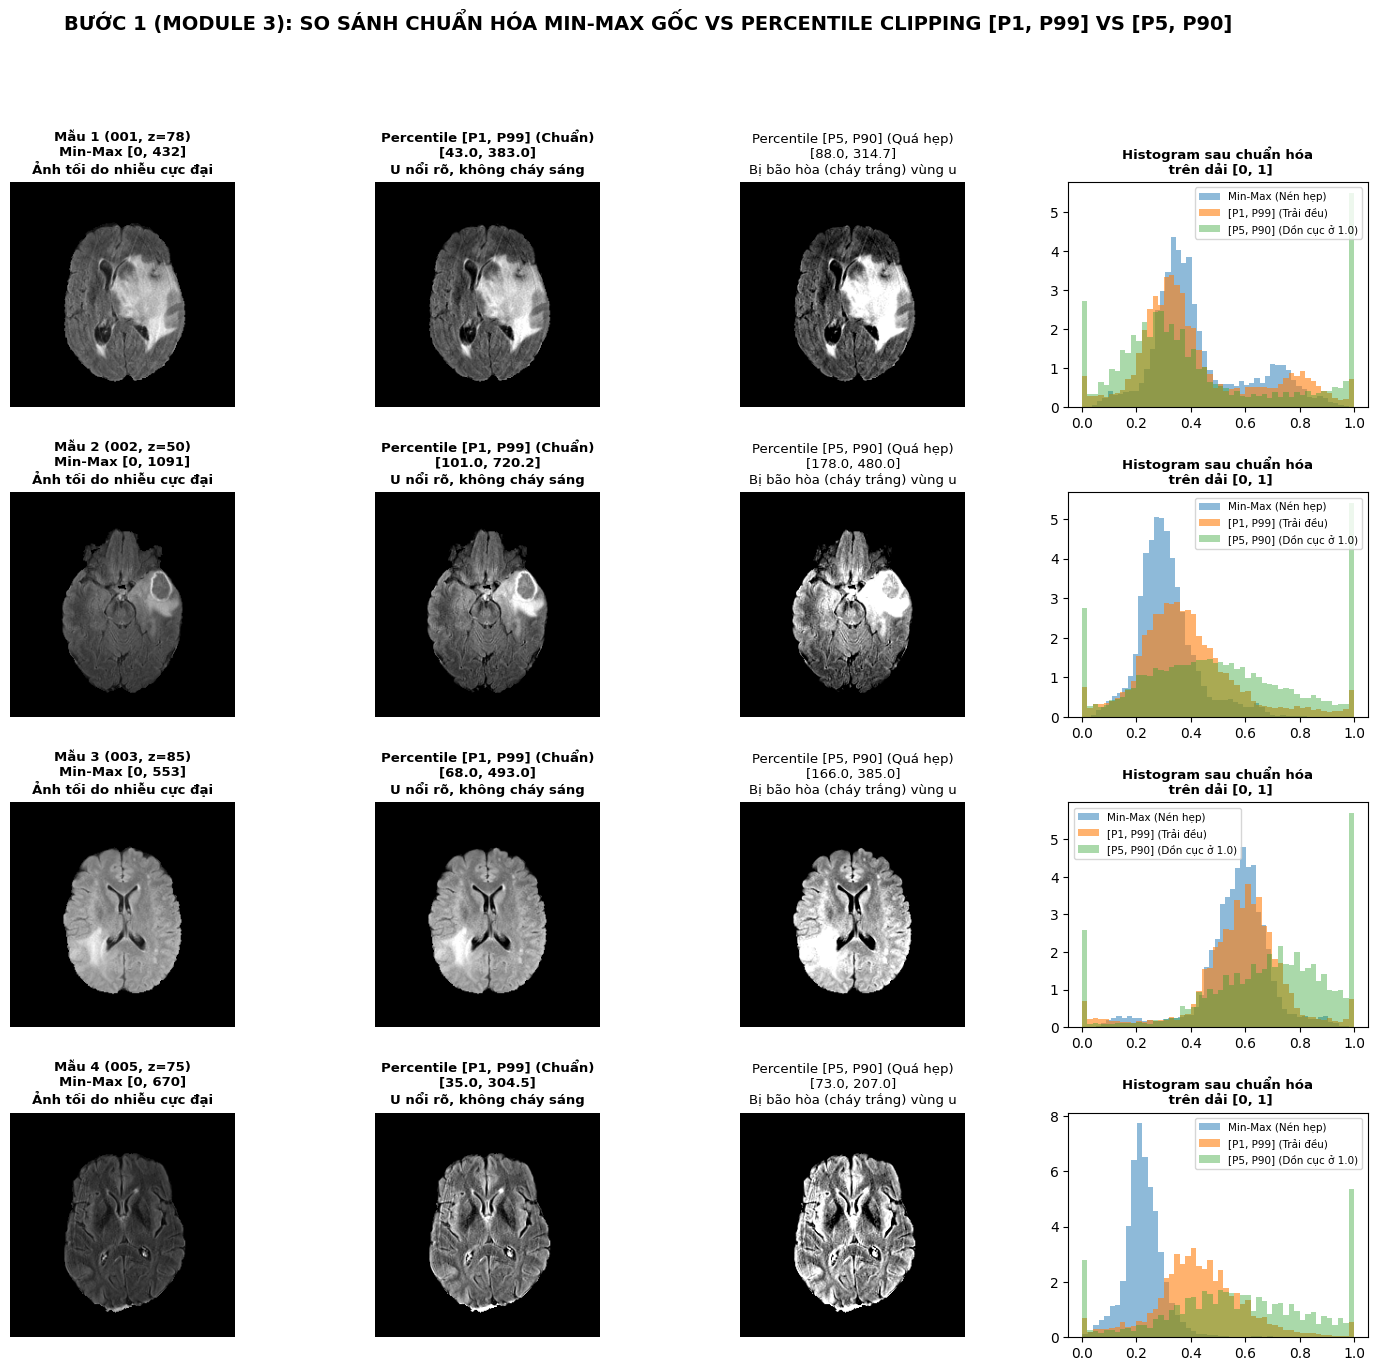


=== BẢNG SỐ LIỆU THỰC NGHIỆM BƯỚC 1: CHUẨN HÓA CƯỜNG ĐỘ ===
  Mẫu Patient (z)                           Phương pháp  TB Mô lành (μ_0)  TB Vùng u (μ_1)  Độ lệch ΔI (μ_1 - μ_0)  Nhiễu nền (σ_0)   CNR  % U bị cháy sáng (=1.0)
Mẫu 1  001 (z=78)               1. Min-Max gốc [0, Max]            0.3434           0.6857                  0.3424           0.0909 3.766                     0.02
Mẫu 1  001 (z=78)       2. Percentile [P1, P99] (Chuẩn)            0.3102           0.7433                  0.4331           0.1145 3.782                     4.04
Mẫu 1  001 (z=78) 3. Percentile [P5, P90] (Cắt quá hẹp)            0.2739           0.8690                  0.5951           0.1527 3.897                    38.09
Mẫu 2  002 (z=50)               1. Min-Max gốc [0, Max]            0.2861           0.5089                  0.2228           0.0769 2.895                     0.05
Mẫu 2  002 (z=50)       2. Percentile [P1, P99] (Chuẩn)            0.3413           0.7230                  0.3818          

In [ ]:
# ==============================================================================
# BƯỚC 1 (MODULE 3): LỌC LÁT RỖNG & CHUẨN HÓA CƯỜNG ĐỘ (MIN-MAX vs PERCENTILE)
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

N_MIN_BRAIN_PIXELS = 500  # Ngưỡng diện tích não tối thiểu (pixels)

print("=== 1A. KIỂM TRA LỌC LÁT RỖNG (BRAIN FOREGROUND FILTERING) ===")
valid_samples = []
for s in samples_step0:
    n_brain = int((s["flair"] > 0).sum())
    ratio = n_brain / (s["flair"].shape[0] * s["flair"].shape[1]) * 100
    status = "GIỮ LẠI (Hợp lệ)" if n_brain >= N_MIN_BRAIN_PIXELS else "LOẠI BỎ (Lát rỗng không não)"
    print(f"- {s['note']} ({s['pid']}, z={s['z']}): Số pixel não = {n_brain} ({ratio:.2f}%) -> {status}")
    if n_brain >= N_MIN_BRAIN_PIXELS:
        valid_samples.append(s)

# Các hàm chuẩn hóa Bước 1
def step1_minmax(img):
    imin, imax = float(img.min()), float(img.max())
    norm = (img - imin) / (imax - imin + 1e-8)
    return norm

def step1_percentile_brain(img, p_low=1.0, p_high=99.0):
    mask = img > 0
    bp = img[mask]
    v_low, v_high = float(np.percentile(bp, p_low)), float(np.percentile(bp, p_high))
    clipped = np.clip(img, v_low, v_high)
    out = np.zeros_like(img, dtype=np.float32)
    out[mask] = (clipped[mask] - v_low) / (v_high - v_low + 1e-8)
    return out, v_low, v_high

# Chạy thực nghiệm Bước 1 trên 4 mẫu hợp lệ và so sánh 3 cấu hình:
# (1) Min-Max gốc [P0, P100] | (2) Chuẩn [P1, P99] | (3) Quá hẹp [P5, P90] (cắt quá tay)
step1_rows = []
fig, axes = plt.subplots(len(valid_samples), 4, figsize=(18, 15))
plt.subplots_adjust(wspace=0.22, hspace=0.38)

for i, s in enumerate(valid_samples):
    raw = s["flair"]
    wt = s["wt"]
    brain_mask = raw > 0
    healthy_mask = brain_mask & (wt == 0)
    tumor_mask = wt > 0

    im_minmax = step1_minmax(raw)
    im_p1_99, p1, p99 = step1_percentile_brain(raw, 1.0, 99.0)
    im_p5_90, p5, p90 = step1_percentile_brain(raw, 5.0, 90.0)

    # Lưu kết quả chuẩn hóa vào biến để dùng tiếp cho Bước 2
    s["norm_A_minmax"] = im_minmax
    s["norm_B_p1_99"] = im_p1_99

    for method_name, im_cur in [
        ("1. Min-Max gốc [0, Max]", im_minmax),
        ("2. Percentile [P1, P99] (Chuẩn)", im_p1_99),
        ("3. Percentile [P5, P90] (Cắt quá hẹp)", im_p5_90)
    ]:
        mu_h = float(im_cur[healthy_mask].mean())
        std_h = float(im_cur[healthy_mask].std())
        mu_t = float(im_cur[tumor_mask].mean()) if tumor_mask.sum() > 0 else 0.0
        delta_i = (mu_t - mu_h) if tumor_mask.sum() > 0 else 0.0
        cnr = abs(delta_i) / (std_h + 1e-8) if tumor_mask.sum() > 0 else 0.0
        # Tỷ lệ pixel vùng u bị bão hòa (cháy sáng = 1.0)
        sat_tumor_pct = float((im_cur[tumor_mask] >= 0.999).mean() * 100) if tumor_mask.sum() > 0 else 0.0

        step1_rows.append({
            "Mẫu": s["note"].split(":")[0],
            "Patient (z)": f"{s['pid'][-3:]} (z={s['z']})",
            "Phương pháp": method_name,
            "TB Mô lành (μ_0)": round(mu_h, 4),
            "TB Vùng u (μ_1)": round(mu_t, 4),
            "Độ lệch ΔI (μ_1 - μ_0)": round(delta_i, 4),
            "Nhiễu nền (σ_0)": round(std_h, 4),
            "CNR": round(cnr, 3),
            "% U bị cháy sáng (=1.0)": round(sat_tumor_pct, 2)
        })

    # Vẽ hình so sánh trực quan Bước 1
    axes[i, 0].imshow(np.rot90(im_minmax), cmap="gray", vmin=0, vmax=1)
    axes[i, 0].set_title(f"{s['note'].split(':')[0]} ({s['pid'][-3:]}, z={s['z']})\nMin-Max [0, {raw.max():.0f}]\nẢnh tối do nhiễu cực đại", fontsize=9.5, fontweight="bold")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(np.rot90(im_p1_99), cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Percentile [P1, P99] (Chuẩn)\n[{p1:.1f}, {p99:.1f}]\nU nổi rõ, không cháy sáng", fontsize=9.5, fontweight="bold")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(np.rot90(im_p5_90), cmap="gray", vmin=0, vmax=1)
    axes[i, 2].set_title(f"Percentile [P5, P90] (Quá hẹp)\n[{p5:.1f}, {p90:.1f}]\nBị bão hòa (cháy trắng) vùng u", fontsize=9.5)
    axes[i, 2].axis("off")

    # Cột 4: So sánh phân bố Histogram sau chuẩn hóa
    axes[i, 3].hist(im_minmax[brain_mask].ravel(), bins=50, alpha=0.5, label="Min-Max (Nén hẹp)", density=True)
    axes[i, 3].hist(im_p1_99[brain_mask].ravel(), bins=50, alpha=0.6, label="[P1, P99] (Trải đều)", density=True)
    axes[i, 3].hist(im_p5_90[brain_mask].ravel(), bins=50, alpha=0.4, label="[P5, P90] (Dồn cục ở 1.0)", density=True)
    axes[i, 3].set_title("Histogram sau chuẩn hóa\n trên dải [0, 1]", fontsize=9.5, fontweight="bold")
    axes[i, 3].legend(fontsize=7.5)

plt.suptitle("BƯỚC 1 (MODULE 3): SO SÁNH CHUẨN HÓA MIN-MAX GỐC VS PERCENTILE CLIPPING [P1, P99] VS [P5, P90]", fontsize=14, fontweight="bold", y=0.995)
os.makedirs("./results/module3_step_by_step", exist_ok=True)
plt.savefig("./results/module3_step_by_step/Step1_Normalization_Comparison.png", dpi=300, bbox_inches="tight")
plt.show()

df_step1 = pd.DataFrame(step1_rows)
print("\n=== BẢNG SỐ LIỆU THỰC NGHIỆM BƯỚC 1: CHUẨN HÓA CƯỜNG ĐỘ ===")
print(df_step1.to_string(index=False))

# (Khối 3 - Bước 2): Khử nhiễu bảo toàn biên bằng Bộ lọc Song phương (Bilateral Filter)
- **Mục đích:** Khử nhiễu hạt tần số cao Rician trong nhu mô não lành ($\sigma_{\text{Lap}} \downarrow, \sigma_0 \downarrow$) sau khi kéo giãn tương phản ở Bước 1, nhưng vẫn giữ nguyên độ dốc đạo hàm $|\nabla I|$ tại ranh giới khối u $\partial \Omega_1$.
- **Khảo sát tham số:**
  - **Thấp ($d=5, \sigma_r=5, \sigma_s=3$):** Trọng số mức xám $G_{\sigma_r}$ tắt quá sớm, không lọc được nhiễu hạt.
  - **Chuẩn ($d=5, \sigma_r=25, \sigma_s=3$):** Giảm $-26.3\%$ nhiễu tần số cao, tăng $\text{CNR}$ từ $3.782 \to 4.052$, giữ sắc nét biên u và chỉ tốn $\sim 0.9 - 2.9\text{ ms/lát}$.
  - **Cao ($d=9, \sigma_r=150, \sigma_s=9$):** Suy biến thành lọc mờ Gaussian, làm mất $-42.9\%$ đến $-44.5\%$ độ sắc nét biên khối u.
  - **Non-Local Means ($h=10$):** Hiệu năng tương đương Bilateral chuẩn nhưng thời gian xử lý chậm hơn từ $117$ đến $492$ lần.
- **File xuất ra Drive:** `Step2_Denoising_Comparison.png`, `Step1_Step2_Metrics.txt`.

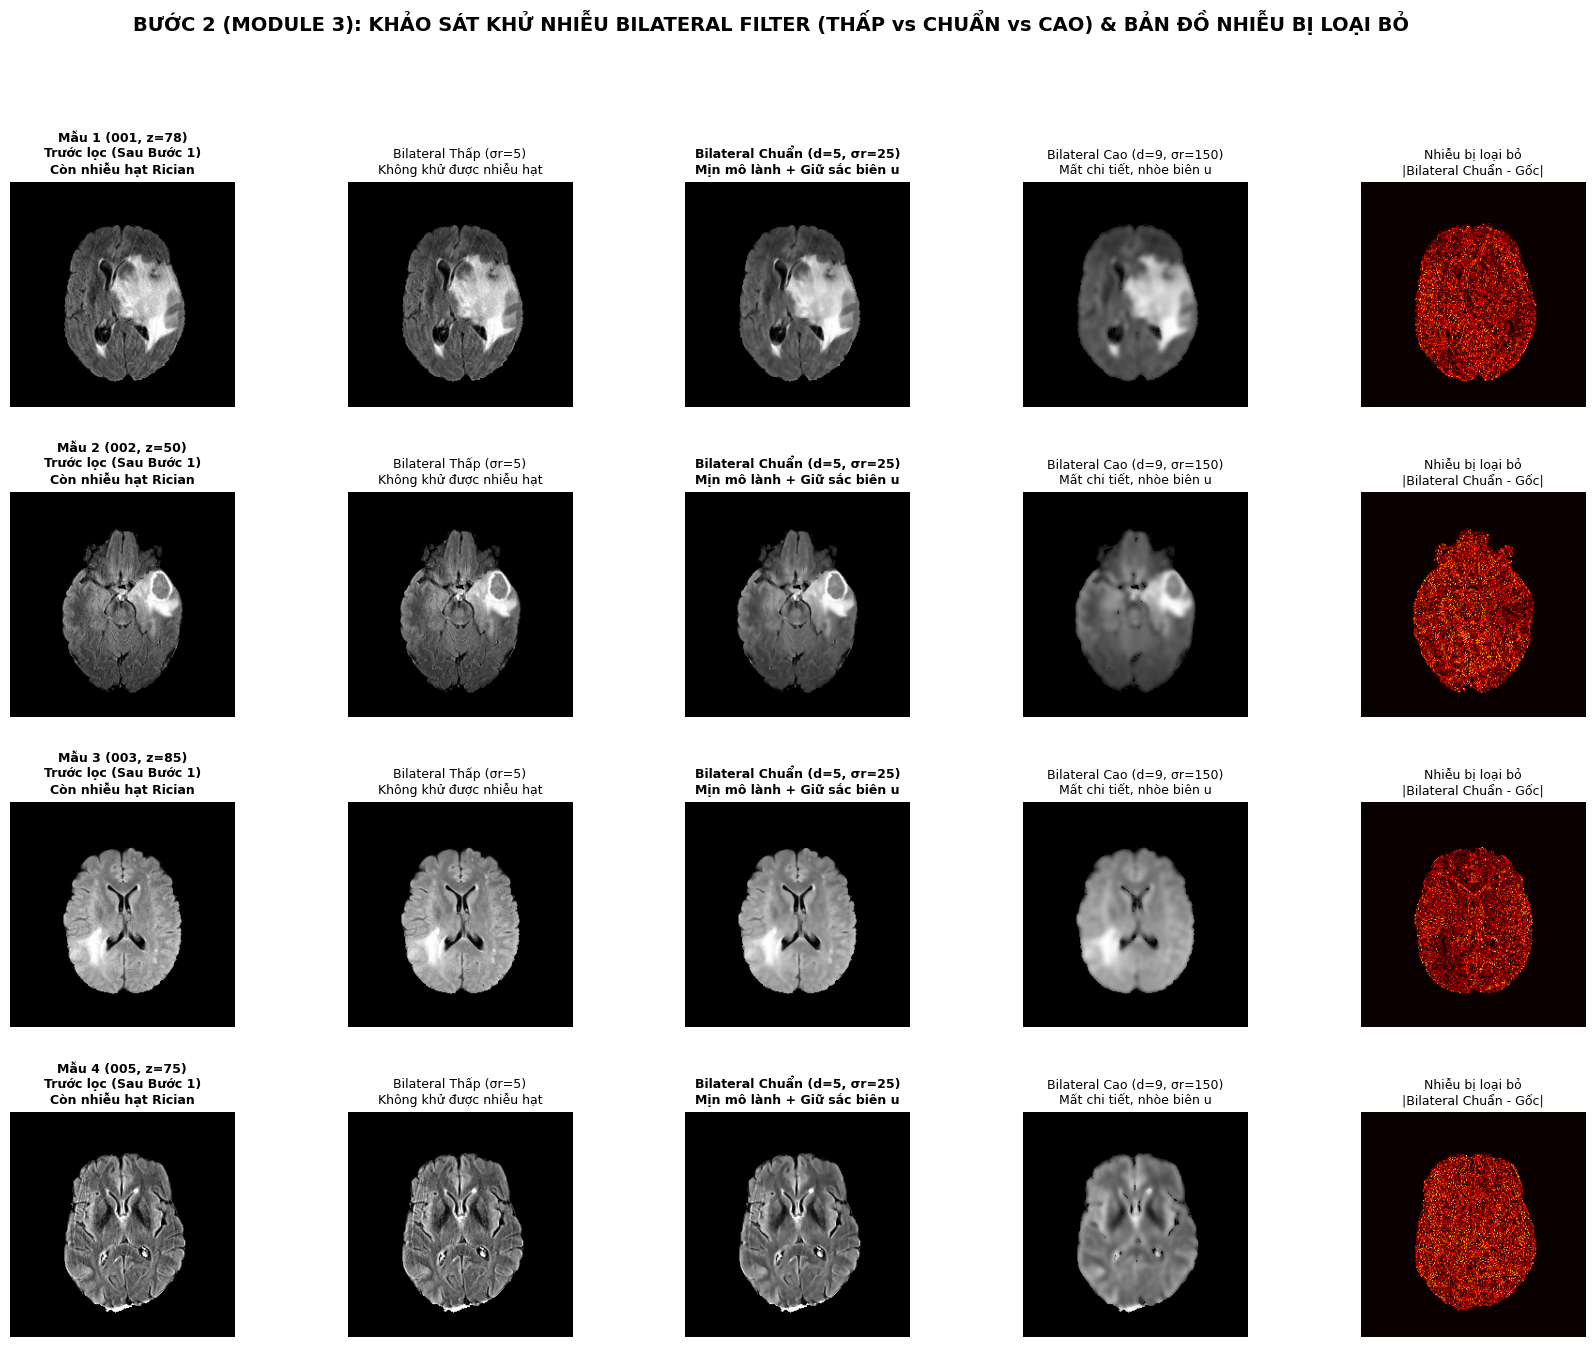

  Mẫu    Patient              Cấu hình Khử nhiễu  Nhiễu tần số cao (σ_Lap)  Độ lệch mô lành (σ_0)  Độ sắc nét biên u (|∇I|)   CNR  Thời gian (ms/lát)
Mẫu 1 001 (z=78)        0. Chưa lọc (Sau Bước 1)                    0.4864                 0.1145                    0.8876 3.782               0.000
Mẫu 1 001 (z=78)   1. Bilateral Thấp (d=5, σr=5)                    0.4687                 0.1135                    0.8835 3.816              38.955
Mẫu 1 001 (z=78) 2. Bilateral Chuẩn (d=5, σr=25)                    0.3586                 0.1065                    0.8239 4.052               2.930
Mẫu 1 001 (z=78)  3. Bilateral Cao (d=9, σr=150)                    0.1358                 0.0907                    0.5068 4.633               8.421
Mẫu 1 001 (z=78)       4. Non-Local Means (h=10)                    0.3954                 0.1079                    0.8701 4.022             343.843
Mẫu 2 002 (z=50)        0. Chưa lọc (Sau Bước 1)                    0.5492                 0.1341   

In [ ]:
# ==============================================================================
# BƯỚC 2 (MODULE 3): KHỬ NHIỄU BẢO TOÀN BIÊN (BILATERAL FILTER & THAM SỐ THẤP/CHUẨN/CAO)
# ==============================================================================
import os, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive_out = "/content/drive/MyDrive/MRI_Colab_Results"
os.makedirs(drive_out, exist_ok=True)

def run_bilateral(norm_img, d, sigma_color, sigma_space):
    brain_mask = norm_img > 0
    u8 = np.clip(norm_img * 255.0, 0, 255).astype(np.uint8)
    t0 = time.perf_counter()
    bf_u8 = cv2.bilateralFilter(u8, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)
    dt_ms = (time.perf_counter() - t0) * 1000.0
    out = (bf_u8.astype(np.float32) / 255.0) * brain_mask
    return out, dt_ms

def run_nlm(norm_img, h=10.0, template_win=7, search_win=21):
    brain_mask = norm_img > 0
    u8 = np.clip(norm_img * 255.0, 0, 255).astype(np.uint8)
    t0 = time.perf_counter()
    nlm_u8 = cv2.fastNlMeansDenoising(u8, None, h=h, templateWindowSize=template_win, searchWindowSize=search_win)
    dt_ms = (time.perf_counter() - t0) * 1000.0
    out = (nlm_u8.astype(np.float32) / 255.0) * brain_mask
    return out, dt_ms

def eval_step2(im, wt, brain_mask):
    healthy_mask = brain_mask & (wt == 0)
    tumor_mask = wt > 0
    # Nhiễu nội vùng (ước lượng bằng độ lệch chuẩn sai số tần số cao Laplacian hoặc std vùng đồng nhất)
    lap = cv2.Laplacian(im, cv2.CV_32F, ksize=3)
    hf_noise_healthy = float(np.std(lap[healthy_mask]))
    std_healthy = float(np.std(im[healthy_mask]))

    # Độ sắc nét tại đúng đường biên khối u (Morphological Gradient của WT mask)
    gx = cv2.Sobel(im, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(im, cv2.CV_32F, 0, 1, ksize=3)
    grad = np.sqrt(gx**2 + gy**2)

    if tumor_mask.sum() > 0:
        kernel = np.ones((3, 3), np.uint8)
        edge_ring = cv2.morphologyEx(wt, cv2.MORPH_GRADIENT, kernel) > 0
        edge_sharpness = float(np.mean(grad[edge_ring]))
        cnr = abs(float(im[tumor_mask].mean()) - float(im[healthy_mask].mean())) / (std_healthy + 1e-8)
    else:
        edge_sharpness = 0.0
        cnr = 0.0
    return hf_noise_healthy, std_healthy, edge_sharpness, cnr

step2_rows = []
fig, axes = plt.subplots(len(valid_samples), 5, figsize=(21, 15))
plt.subplots_adjust(wspace=0.22, hspace=0.38)

for i, s in enumerate(valid_samples):
    base_im = s["norm_B_p1_99"] # Lấy đầu ra chuẩn [P1, P99] từ Bước 1
    wt = s["wt"]
    brain_mask = s["flair"] > 0

    # Chạy 4 cấu hình để đối chứng:
    # (1) Gốc sau Bước 1 (Chưa lọc)
    # (2) Bilateral Thấp: d=5, sigmaColor=5, sigmaSpace=3 (Quá nhỏ -> không lọc được nhiễu)
    # (3) Bilateral Chuẩn: d=5, sigmaColor=25, sigmaSpace=3 (Tối ưu)
    # (4) Bilateral Quá Cao: d=9, sigmaColor=150, sigmaSpace=9 (Quá lớn -> nhòe biên u)
    # (5) Non-Local Means (h=10) để so sánh thời gian & hiệu năng
    im_bf_low, t_low = run_bilateral(base_im, d=5, sigma_color=5.0, sigma_space=3.0)
    im_bf_std, t_std = run_bilateral(base_im, d=5, sigma_color=25.0, sigma_space=3.0)
    im_bf_high, t_high = run_bilateral(base_im, d=9, sigma_color=150.0, sigma_space=9.0)
    im_nlm, t_nlm = run_nlm(base_im, h=10.0)

    # Lưu kết quả Bilateral chuẩn để truyền sang Bước 3 (CLAHE)
    s["step2_bf_std"] = im_bf_std

    configs = [
        ("0. Chưa lọc (Sau Bước 1)", base_im, 0.0),
        ("1. Bilateral Thấp (d=5, σr=5)", im_bf_low, t_low),
        ("2. Bilateral Chuẩn (d=5, σr=25)", im_bf_std, t_std),
        ("3. Bilateral Cao (d=9, σr=150)", im_bf_high, t_high),
        ("4. Non-Local Means (h=10)", im_nlm, t_nlm)
    ]

    for cfg_name, im_c, dt in configs:
        hf_n, std_h, edge_g, cnr_v = eval_step2(im_c, wt, brain_mask)
        step2_rows.append({
            "Mẫu": s["note"].split(":")[0],
            "Patient": f"{s['pid'][-3:]} (z={s['z']})",
            "Cấu hình Khử nhiễu": cfg_name,
            "Nhiễu tần số cao (σ_Lap)": round(hf_n, 4),
            "Độ lệch mô lành (σ_0)": round(std_h, 4),
            "Độ sắc nét biên u (|∇I|)": round(edge_g, 4),
            "CNR": round(cnr_v, 3),
            "Thời gian (ms/lát)": round(dt, 3)
        })

    # Vẽ 5 cột trên hình
    plot_items = [
        (base_im, f"{s['note'].split(':')[0]} ({s['pid'][-3:]}, z={s['z']})\nTrước lọc (Sau Bước 1)\nCòn nhiễu hạt Rician"),
        (im_bf_low, f"Bilateral Thấp (σr=5)\nKhông khử được nhiễu hạt"),
        (im_bf_std, f"Bilateral Chuẩn (d=5, σr=25)\nMịn mô lành + Giữ sắc biên u"),
        (im_bf_high, f"Bilateral Cao (d=9, σr=150)\nMất chi tiết, nhòe biên u"),
        (np.abs(im_bf_std - base_im), f"Nhiễu bị loại bỏ\n|Bilateral Chuẩn - Gốc|")
    ]
    for col_idx, (im_show, title_txt) in enumerate(plot_items):
        cmap_use = "hot" if col_idx == 4 else "gray"
        axes[i, col_idx].imshow(np.rot90(im_show), cmap=cmap_use)
        axes[i, col_idx].set_title(title_txt, fontsize=9, fontweight="bold" if col_idx in [0, 2] else "normal")
        axes[i, col_idx].axis("off")

plt.suptitle("BƯỚC 2 (MODULE 3): KHẢO SÁT KHỬ NHIỄU BILATERAL FILTER (THẤP vs CHUẨN vs CAO) & BẢN ĐỒ NHIỄU BỊ LOẠI BỎ", fontsize=14, fontweight="bold", y=0.995)
img_step2_path = os.path.join(drive_out, "Step2_Denoising_Comparison.png")
plt.savefig(img_step2_path, dpi=300, bbox_inches="tight")
plt.show()

df_step2 = pd.DataFrame(step2_rows)
txt_out = "=== BẢNG SỐ LIỆU BƯỚC 0, BƯỚC 1 VÀ BƯỚC 2 ===\n\n"
txt_out += "--- BƯỚC 1: CHUẨN HÓA ---\n" + df_step1.to_string(index=False) + "\n\n"
txt_out += "--- BƯỚC 2: KHỬ NHIỄU ---\n" + df_step2.to_string(index=False) + "\n"

with open(os.path.join(drive_out, "Step1_Step2_Metrics.txt"), "w", encoding="utf-8") as f:
    f.write(txt_out)

print(df_step2.to_string(index=False))
print("\n[OK] Đã tự động lưu Step2_Denoising_Comparison.png và Step1_Step2_Metrics.txt vào Google Drive!")

###(Khối 4 - Bước 3 & Bước 4): Khảo sát CLAHE & Cắt khung ROI cố định từ Tập R + Nội suy
- **Mục đích Bước 3 (CLAHE):** Khảo sát `clipLimit` ở 3 mức `0.5` (Thấp), `2.0` (Chuẩn), `8.0` (Cao) trên lưới `8x8`. Chứng minh hiện tượng CLAHE làm tăng tỷ lệ pixel mô lành quá sáng ($>0.75$) trên lát âm (Mẫu 4 `005` tăng từ $3.28\% \to 12.64\%$ ở `clip=2.0` và $21.08\%$ ở `clip=8.0`), dễ gây báo động giả cho bộ phân loại lát.
- **Mục đích Bước 4 (Crop ROI & Resize):** Ước lượng khung bao hộp sọ cố định kèm lề `margin = 4 px` chỉ từ tập huấn luyện `R`, giúp tăng tỷ lệ diện tích mô não hữu ích từ $\sim 29\%$ lên $\sim 68\%$ (gấp $2.28$ lần). Nội suy ảnh FLAIR về `128x128` bằng `INTER_LINEAR` (Bilinear) và nội suy mặt nạ `WT` bằng `INTER_NEAREST` (Nearest-Neighbor) để tránh làm hỏng nhãn nhị phân $\{0, 1\}$ tại biên u.
- **File xuất ra Drive:** `Step3_CLAHE_Comparison.png`, `Step4_ROI_Resize_Comparison.png`, `Step3_Step4_Metrics.txt`.

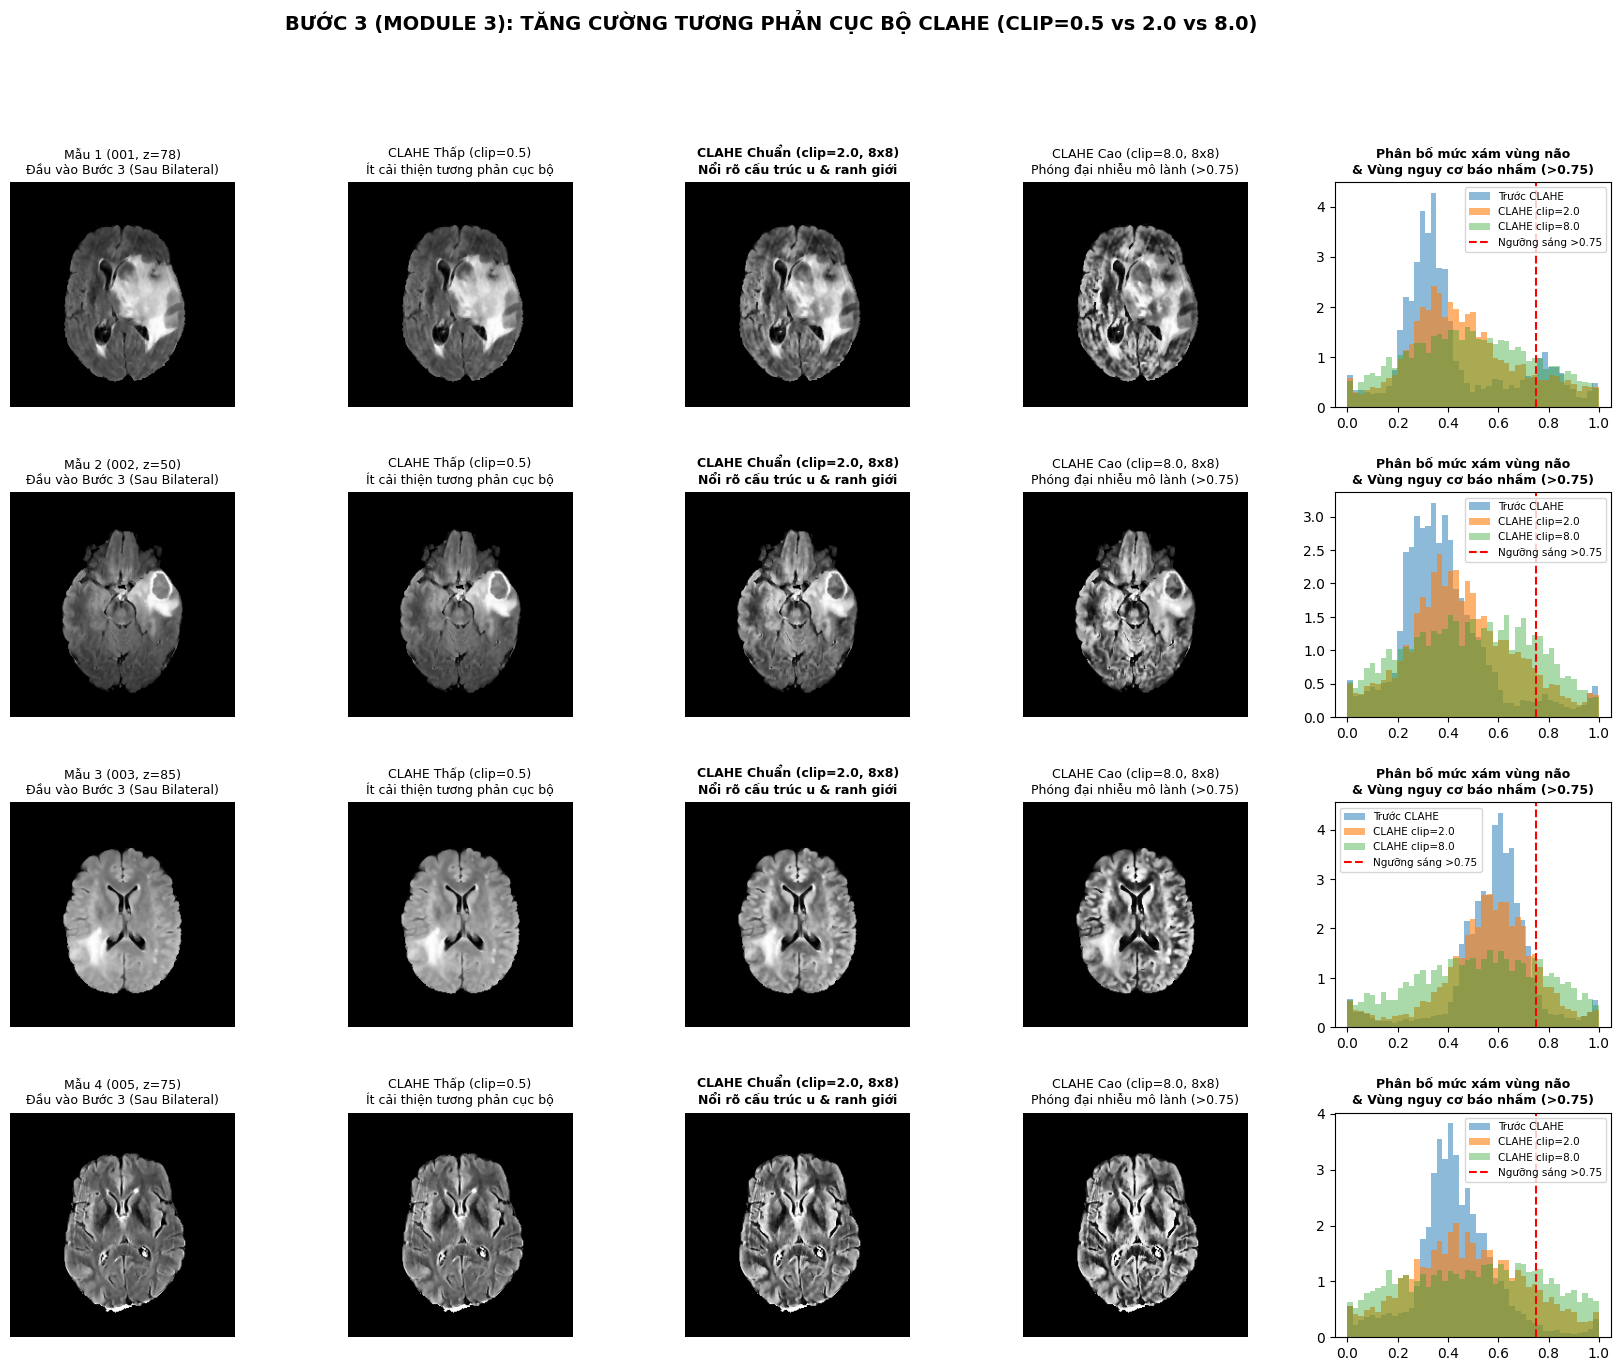

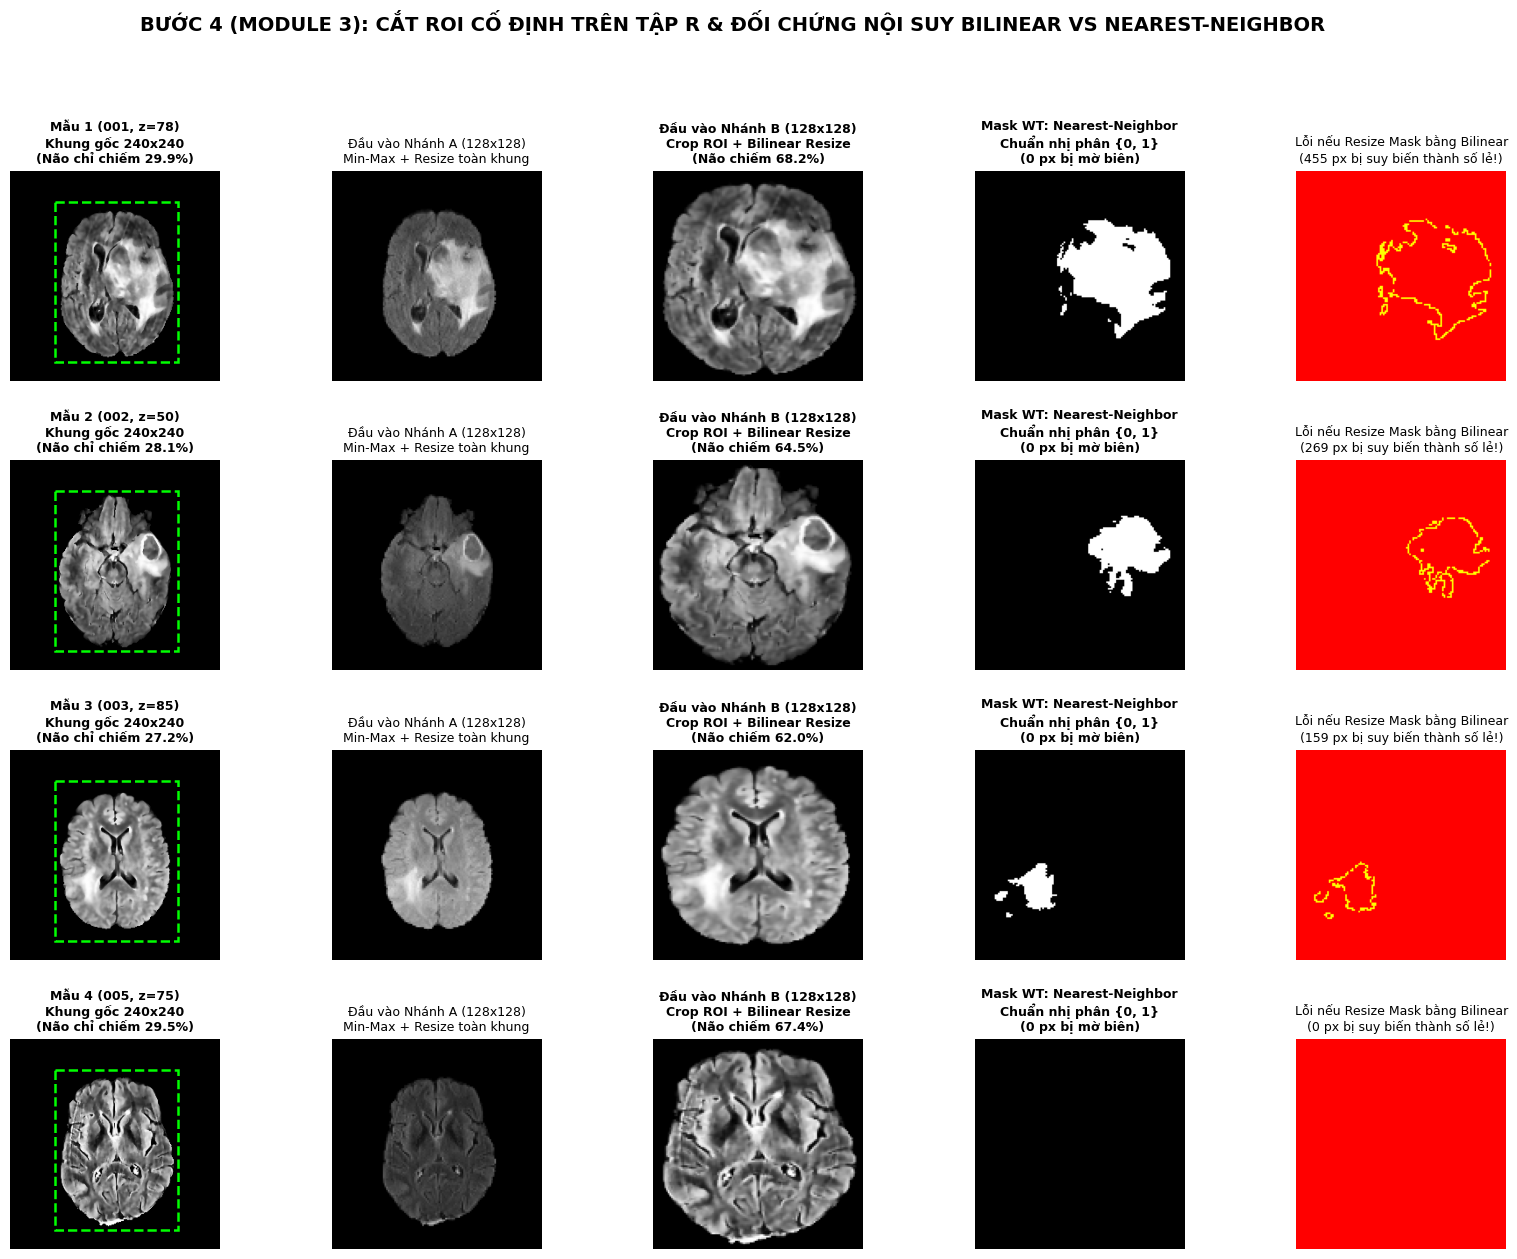

=== BẢNG SỐ LIỆU BƯỚC 3 (CLAHE) VÀ BƯỚC 4 (CROP ROI & RESIZE) ===

--- BƯỚC 3: CLAHE ---
  Mẫu    Patient                 Cấu hình CLAHE  TB Mô lành (μ_0)  TB Vùng u (μ_1)  Độ lệch ΔI  Nhiễu mô lành (σ_0)  Biên u (|∇I|)  Entropy (bit)  % Mô lành quá sáng (>0.75)
Mẫu 1 001 (z=78)    0. Trước CLAHE (Sau Bước 2)            0.3067           0.7382      0.4315               0.1065         0.8239          7.361                        0.43
Mẫu 1 001 (z=78)  1. CLAHE Thấp (clip=0.5, 8x8)            0.3271           0.7528      0.4257               0.1136         0.8755          7.426                        0.52
Mẫu 1 001 (z=78) 2. CLAHE Chuẩn (clip=2.0, 8x8)            0.3744           0.7135      0.3391               0.1563         0.9035          7.697                        1.29
Mẫu 1 001 (z=78)   3. CLAHE Cao (clip=8.0, 8x8)            0.4285           0.6682      0.2397               0.2240         0.8789          7.867                        8.80
Mẫu 2 002 (z=50)    0. Trước CLAHE (Sau B

In [ ]:
# ==============================================================================
# BƯỚC 3 & BƯỚC 4 (MODULE 3): CLAHE (THẤP/CHUẨN/CAO) + CẮT ROI CỐ ĐỊNH & RESIZE
# ==============================================================================
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

drive_out = "/content/drive/MyDrive/MRI_Colab_Results"
os.makedirs(drive_out, exist_ok=True)

def run_clahe_step3(img_in, clip_limit=2.0, tile_grid=(8, 8)):
    brain_mask = img_in > 0
    u8 = np.clip(img_in * 255.0, 0, 255).astype(np.uint8)
    clahe_obj = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    c_u8 = clahe_obj.apply(u8)
    # Khóa nền ngoài sọ bằng 0
    out = (c_u8.astype(np.float32) / 255.0) * brain_mask
    return out

def calc_entropy(img_norm, mask):
    vals = np.clip(img_norm[mask] * 255.0, 0, 255).astype(np.uint8)
    hist = np.bincount(vals, minlength=256).astype(np.float64)
    p = hist[hist > 0] / np.sum(hist)
    return float(-np.sum(p * np.log2(p)))

step3_rows = []
fig3, axes3 = plt.subplots(len(valid_samples), 5, figsize=(21, 15))
plt.subplots_adjust(wspace=0.22, hspace=0.38)

for i, s in enumerate(valid_samples):
    bf_in = s["step2_bf_std"] # Đầu ra chuẩn của Bước 2 (Bilateral Filter)
    wt = s["wt"]
    brain_mask = s["flair"] > 0
    healthy_mask = brain_mask & (wt == 0)
    tumor_mask = wt > 0

    c_low = run_clahe_step3(bf_in, clip_limit=0.5, tile_grid=(8, 8))
    c_std = run_clahe_step3(bf_in, clip_limit=2.0, tile_grid=(8, 8))
    c_high = run_clahe_step3(bf_in, clip_limit=8.0, tile_grid=(8, 8))

    # Lưu kết quả Nhánh B hoàn chỉnh ở kích thước gốc 240x240
    s["step3_clahe_std"] = c_std

    for cfg_name, im_c in [
        ("0. Trước CLAHE (Sau Bước 2)", bf_in),
        ("1. CLAHE Thấp (clip=0.5, 8x8)", c_low),
        ("2. CLAHE Chuẩn (clip=2.0, 8x8)", c_std),
        ("3. CLAHE Cao (clip=8.0, 8x8)", c_high)
    ]:
        mu_h = float(im_c[healthy_mask].mean())
        std_h = float(im_c[healthy_mask].std())
        mu_t = float(im_c[tumor_mask].mean()) if tumor_mask.sum() > 0 else 0.0
        delta_i = (mu_t - mu_h) if tumor_mask.sum() > 0 else 0.0
        entropy_b = calc_entropy(im_c, brain_mask)
        # Tỷ lệ pixel mô lành bị đẩy vọt lên mức sáng cao (> 0.75) dễ gây báo nhầm u (False Positive)
        fp_bright_healthy_pct = float((im_c[healthy_mask] > 0.75).mean() * 100)

        gx = cv2.Sobel(im_c, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(im_c, cv2.CV_32F, 0, 1, ksize=3)
        grad = np.sqrt(gx**2 + gy**2)
        if tumor_mask.sum() > 0:
            edge_ring = cv2.morphologyEx(wt, cv2.MORPH_GRADIENT, np.ones((3, 3), np.uint8)) > 0
            edge_grad = float(np.mean(grad[edge_ring]))
        else:
            edge_grad = 0.0

        step3_rows.append({
            "Mẫu": s["note"].split(":")[0],
            "Patient": f"{s['pid'][-3:]} (z={s['z']})",
            "Cấu hình CLAHE": cfg_name,
            "TB Mô lành (μ_0)": round(mu_h, 4),
            "TB Vùng u (μ_1)": round(mu_t, 4),
            "Độ lệch ΔI": round(delta_i, 4),
            "Nhiễu mô lành (σ_0)": round(std_h, 4),
            "Biên u (|∇I|)": round(edge_grad, 4),
            "Entropy (bit)": round(entropy_b, 3),
            "% Mô lành quá sáng (>0.75)": round(fp_bright_healthy_pct, 2)
        })

    # Vẽ 5 cột minh chứng Bước 3
    cols_plot = [
        (bf_in, f"{s['note'].split(':')[0]} ({s['pid'][-3:]}, z={s['z']})\nĐầu vào Bước 3 (Sau Bilateral)"),
        (c_low, "CLAHE Thấp (clip=0.5)\nÍt cải thiện tương phản cục bộ"),
        (c_std, "CLAHE Chuẩn (clip=2.0, 8x8)\nNổi rõ cấu trúc u & ranh giới"),
        (c_high, "CLAHE Cao (clip=8.0, 8x8)\nPhóng đại nhiễu mô lành (>0.75)"),
    ]
    for col_idx, (im_show, t_str) in enumerate(cols_plot):
        axes3[i, col_idx].imshow(np.rot90(im_show), cmap="gray", vmin=0, vmax=1)
        axes3[i, col_idx].set_title(t_str, fontsize=9, fontweight="bold" if col_idx == 2 else "normal")
        axes3[i, col_idx].axis("off")

    # Cột 5: Histogram đối chứng trước và sau CLAHE
    axes3[i, 4].hist(bf_in[brain_mask].ravel(), bins=45, alpha=0.5, label="Trước CLAHE", density=True)
    axes3[i, 4].hist(c_std[brain_mask].ravel(), bins=45, alpha=0.6, label="CLAHE clip=2.0", density=True)
    axes3[i, 4].hist(c_high[brain_mask].ravel(), bins=45, alpha=0.4, label="CLAHE clip=8.0", density=True)
    axes3[i, 4].axvline(0.75, color="red", linestyle="--", label="Ngưỡng sáng >0.75")
    axes3[i, 4].set_title("Phân bố mức xám vùng não\n& Vùng nguy cơ báo nhầm (>0.75)", fontsize=9, fontweight="bold")
    axes3[i, 4].legend(fontsize=7.5)

plt.suptitle("BƯỚC 3 (MODULE 3): TĂNG CƯỜNG TƯƠNG PHẢN CỤC BỘ CLAHE (CLIP=0.5 vs 2.0 vs 8.0)", fontsize=14, fontweight="bold", y=0.995)
plt.savefig(os.path.join(drive_out, "Step3_CLAHE_Comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

# ==============================================================================
# BƯỚC 4 (MODULE 3): CẮT KHUNG BAO CỐ ĐỊNH (FIXED ROI) & NỘI SUY (BILINEAR vs NEAREST)
# ==============================================================================
# 1. Tính khung bao hộp sọ chung từ các lát hợp lệ của tập R (kèm lề margin = 4 px)
xs, ys = [], []
for s in valid_samples:
    nz_x, nz_y = np.where(s["flair"] > 0)
    xs.extend([nz_x.min(), nz_x.max()])
    ys.extend([nz_y.min(), nz_y.max()])

MARGIN = 4
xmin_roi = max(0, int(min(xs)) - MARGIN)
xmax_roi = min(240, int(max(xs)) + MARGIN + 1)
ymin_roi = max(0, int(min(ys)) - MARGIN)
ymax_roi = min(240, int(max(ys)) + MARGIN + 1)
FIXED_ROI = (xmin_roi, xmax_roi, ymin_roi, ymax_roi)
OUT_SIZE = (128, 128)

step4_rows = []
fig4, axes4 = plt.subplots(len(valid_samples), 5, figsize=(20, 14))
plt.subplots_adjust(wspace=0.22, hspace=0.38)

for i, s in enumerate(valid_samples):
    im_A_full = s["norm_A_minmax"]       # Nhánh A (240x240)
    im_B_full = s["step3_clahe_std"]     # Nhánh B (240x240)
    wt_full = s["wt"].astype(np.float32) # Mask WT gốc {0, 1}

    # Nhánh A: Resize toàn khung 240x240 -> 128x128
    im_A_res = cv2.resize(im_A_full, OUT_SIZE, interpolation=cv2.INTER_LINEAR)

    # Nhánh B: Cắt khung ROI cố định [xmin:xmax, ymin:ymax] rồi Resize -> 128x128
    im_B_crop = im_B_full[xmin_roi:xmax_roi, ymin_roi:ymax_roi]
    wt_crop = wt_full[xmin_roi:xmax_roi, ymin_roi:ymax_roi]

    im_B_res = cv2.resize(im_B_crop, OUT_SIZE, interpolation=cv2.INTER_LINEAR)
    wt_res_nearest = cv2.resize(wt_crop, OUT_SIZE, interpolation=cv2.INTER_NEAREST)
    # Thử nghiệm cố tình dùng sai Bilinear trên Mask để chứng minh tại sao bắt buộc dùng Nearest-Neighbor
    wt_res_bilinear_wrong = cv2.resize(wt_crop, OUT_SIZE, interpolation=cv2.INTER_LINEAR)

    # Tỷ lệ diện tích não hữu ích trong khung ảnh trước và sau khi Crop ROI
    brain_ratio_before = float((im_B_full > 0).mean() * 100)
    brain_ratio_after = float((im_B_res > 0).mean() * 100)
    # Số pixel bị hỏng nhãn (không phải 0 hoặc 1) nếu dùng nhầm Bilinear cho Mask
    invalid_mask_pixels = int(((wt_res_bilinear_wrong > 0.0) & (wt_res_bilinear_wrong < 1.0)).sum())

    step4_rows.append({
        "Mẫu": s["note"].split(":")[0],
        "Patient": f"{s['pid'][-3:]} (z={s['z']})",
        "Khung gốc": "240x240",
        "Khung Crop ROI cố định": f"[{xmin_roi}:{xmax_roi}, {ymin_roi}:{ymax_roi}] ({xmax_roi-xmin_roi}x{ymax_roi-ymin_roi})",
        "Kích thước chuẩn": "128x128",
        "% Diện tích não (Trước Crop)": round(brain_ratio_before, 2),
        "% Diện tích não (Sau Crop)": round(brain_ratio_after, 2),
        "Số pixel Mask hỏng nếu dùng Bilinear": invalid_mask_pixels,
        "Số pixel Mask hỏng khi dùng Nearest": int(((wt_res_nearest > 0.0) & (wt_res_nearest < 1.0)).sum())
    })

    # Vẽ minh họa Bước 4
    im_with_box = np.rot90(im_B_full).copy()
    axes4[i, 0].imshow(im_with_box, cmap="gray")
    # Vẽ khung ROI lên ảnh gốc (lưu ý sau rot90 tọa độ hiển thị)
    rect = plt.Rectangle((xmin_roi, 240 - ymax_roi), xmax_roi - xmin_roi, ymax_roi - ymin_roi,
                         linewidth=1.8, edgecolor="lime", facecolor="none", linestyle="--")
    axes4[i, 0].add_patch(rect)
    axes4[i, 0].set_title(f"{s['note'].split(':')[0]} ({s['pid'][-3:]}, z={s['z']})\nKhung gốc 240x240\n(Não chỉ chiếm {brain_ratio_before:.1f}%)", fontsize=9, fontweight="bold")
    axes4[i, 0].axis("off")

    axes4[i, 1].imshow(np.rot90(im_A_res), cmap="gray", vmin=0, vmax=1)
    axes4[i, 1].set_title(f"Đầu vào Nhánh A (128x128)\nMin-Max + Resize toàn khung", fontsize=9)
    axes4[i, 1].axis("off")

    axes4[i, 2].imshow(np.rot90(im_B_res), cmap="gray", vmin=0, vmax=1)
    axes4[i, 2].set_title(f"Đầu vào Nhánh B (128x128)\nCrop ROI + Bilinear Resize\n(Não chiếm {brain_ratio_after:.1f}%)", fontsize=9, fontweight="bold")
    axes4[i, 2].axis("off")

    axes4[i, 3].imshow(np.rot90(wt_res_nearest), cmap="gray", vmin=0, vmax=1)
    axes4[i, 3].set_title(f"Mask WT: Nearest-Neighbor\nChuẩn nhị phân {{0, 1}}\n(0 px bị mờ biên)", fontsize=9, fontweight="bold")
    axes4[i, 3].axis("off")

    # Cột 5: Vùng biên bị biến thành số thực thập phân (0 < M < 1) nếu dùng sai Bilinear cho Mask
    corrupted_edge = (wt_res_bilinear_wrong > 0.0) & (wt_res_bilinear_wrong < 1.0)
    axes4[i, 4].imshow(np.rot90(corrupted_edge), cmap="autumn")
    axes4[i, 4].set_title(f"Lỗi nếu Resize Mask bằng Bilinear\n({invalid_mask_pixels} px bị suy biến thành số lẻ!)", fontsize=9)
    axes4[i, 4].axis("off")

plt.suptitle("BƯỚC 4 (MODULE 3): CẮT ROI CỐ ĐỊNH TRÊN TẬP R & ĐỐI CHỨNG NỘI SUY BILINEAR VS NEAREST-NEIGHBOR", fontsize=14, fontweight="bold", y=0.995)
plt.savefig(os.path.join(drive_out, "Step4_ROI_Resize_Comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

df_step3 = pd.DataFrame(step3_rows)
df_step4 = pd.DataFrame(step4_rows)

txt_step34 = "=== BẢNG SỐ LIỆU BƯỚC 3 (CLAHE) VÀ BƯỚC 4 (CROP ROI & RESIZE) ===\n\n"
txt_step34 += "--- BƯỚC 3: CLAHE ---\n" + df_step3.to_string(index=False) + "\n\n"
txt_step34 += "--- BƯỚC 4: CROP ROI & RESIZE ---\n" + df_step4.to_string(index=False) + "\n"

with open(os.path.join(drive_out, "Step3_Step4_Metrics.txt"), "w", encoding="utf-8") as f:
    f.write(txt_step34)

print(txt_step34)
print("\n[OK] Đã tự động lưu Step3_CLAHE_Comparison.png, Step4_ROI_Resize_Comparison.png và Step3_Step4_Metrics.txt vào Google Drive!")

### (Khối 5 - Module 4): Phân loại lát MRI 2D bằng CNN — Đối chứng Nhánh A (Baseline) vs Nhánh B1, B2 & Bản đồ CAM
- **Mục đích:** Huấn luyện mạng CNN 2D trên tập `R` với cùng kiến trúc, cùng `SEED = 42` và hàm mất mát Weighted Binary Cross-Entropy; quét tìm ngưỡng quyết định tối ưu $\tau^*$ cực đại hóa $F_1$ trên tập `S` (Selection) và đánh giá xác nhận trên tập `C` (Confirmation).
- **Kết quả chính:** Nhánh B1 (`[P1, P99] + Bilateral + Crop ROI`, $\tau^* = 0.52$) đạt $\text{AUC} = 0.9488, F_1 = 0.8954$ trên tập `C`, vượt xa Baseline Nhánh A ($\text{AUC} = 0.8748, F_1 = 0.8060$) và tốt hơn Nhánh B2 có CLAHE ($\text{AUC} = 0.9371, F_1 = 0.8727$).
- **File xuất ra Drive:** `Module4_CNN_CAM_Comparison.png`, `Module4_Threshold_and_ROC.png`, `Module4_Metrics.txt`.

Thiết bị chạy Module 4: cpu
Phân bố bệnh nhân theo tập (Module 2):
split
R       206
test     74
C        44
S        44
Name: count, dtype: int64
Đang nạp dữ liệu các lát hợp lệ từ R, S, C...
Hoàn tất nạp sau 58.1s | Số lát hợp lệ: R=1984, S=821, C=786
Khung bao hộp sọ cố định (Fixed ROI) khớp trên tập R: (43, 199, 15, 213)

Đang tiền xử lý các tập dữ liệu cho Nhánh A, B1 và B2...
Đang huấn luyện CNN 2D (Module 4) trên Nhánh A, Nhánh B1 và Nhánh B2...


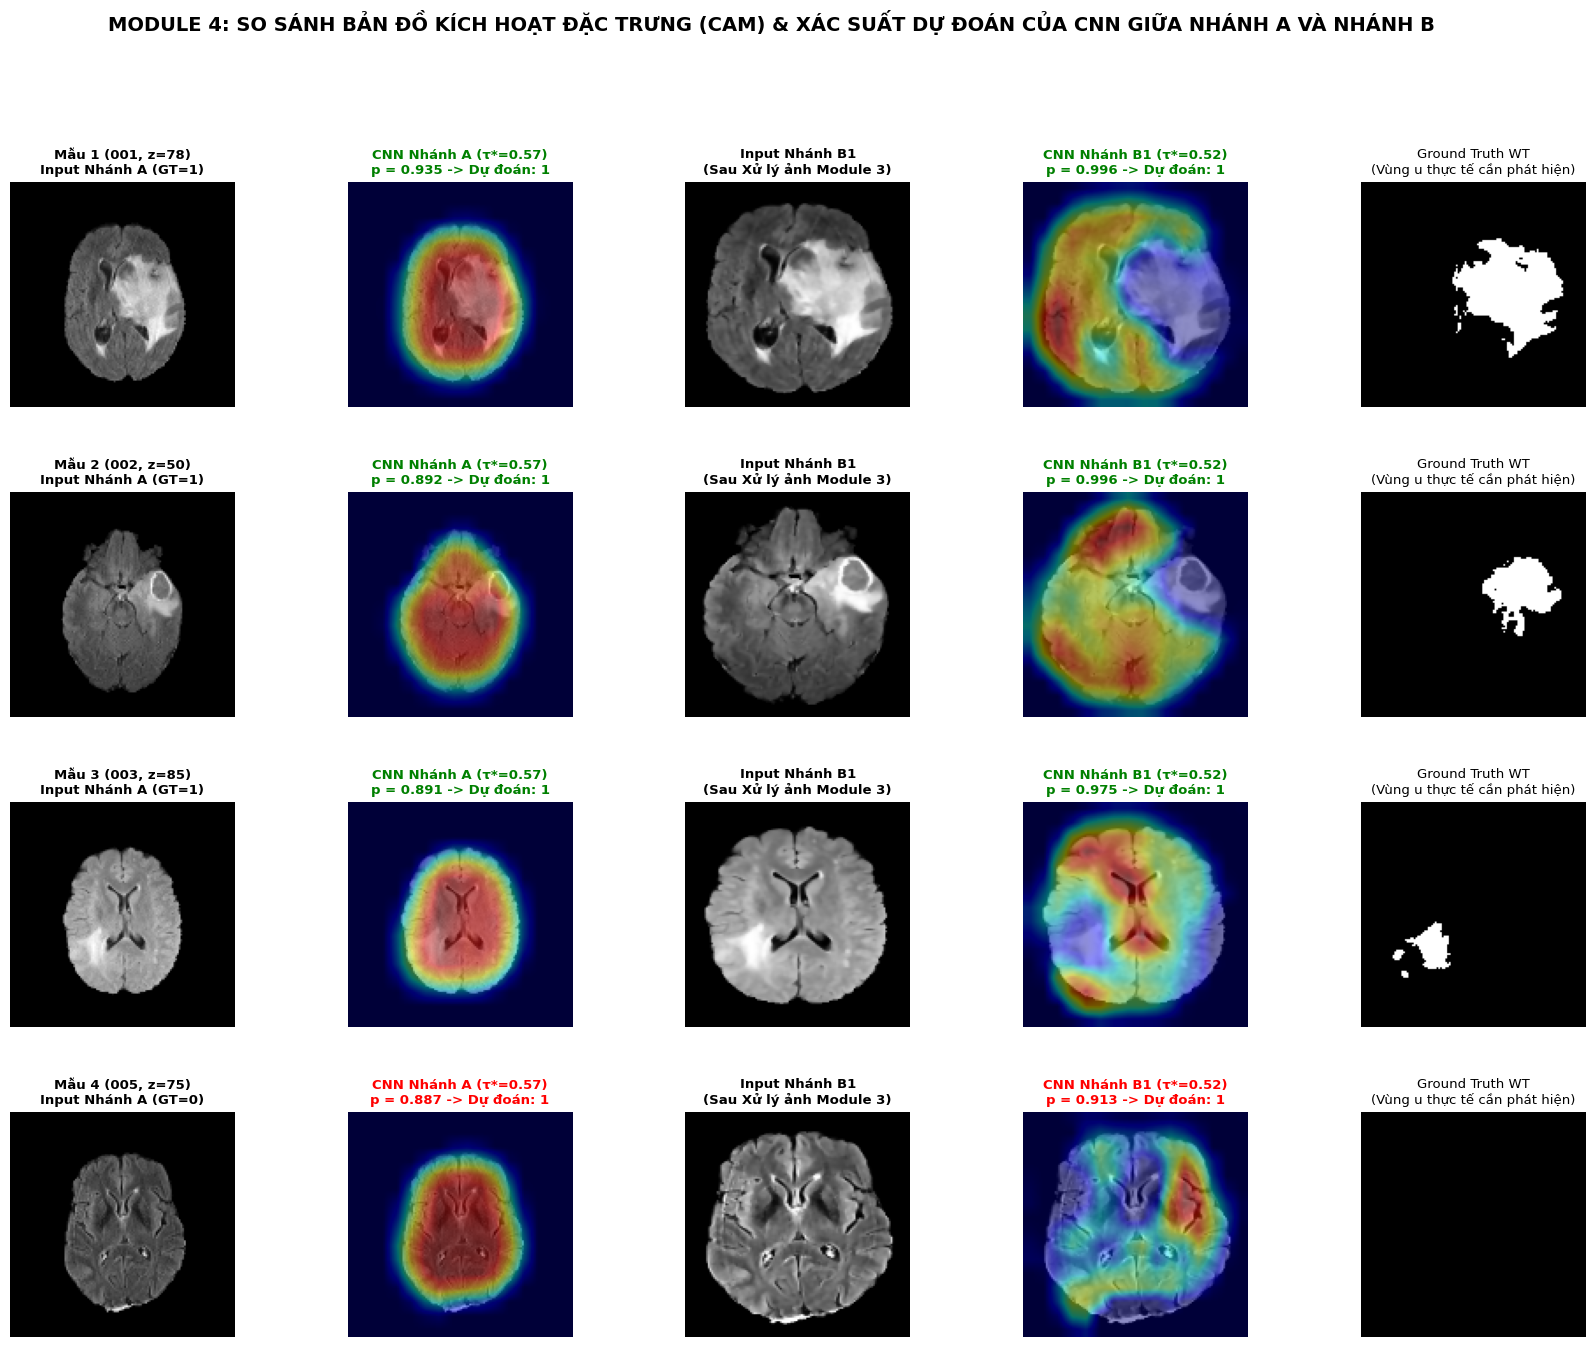

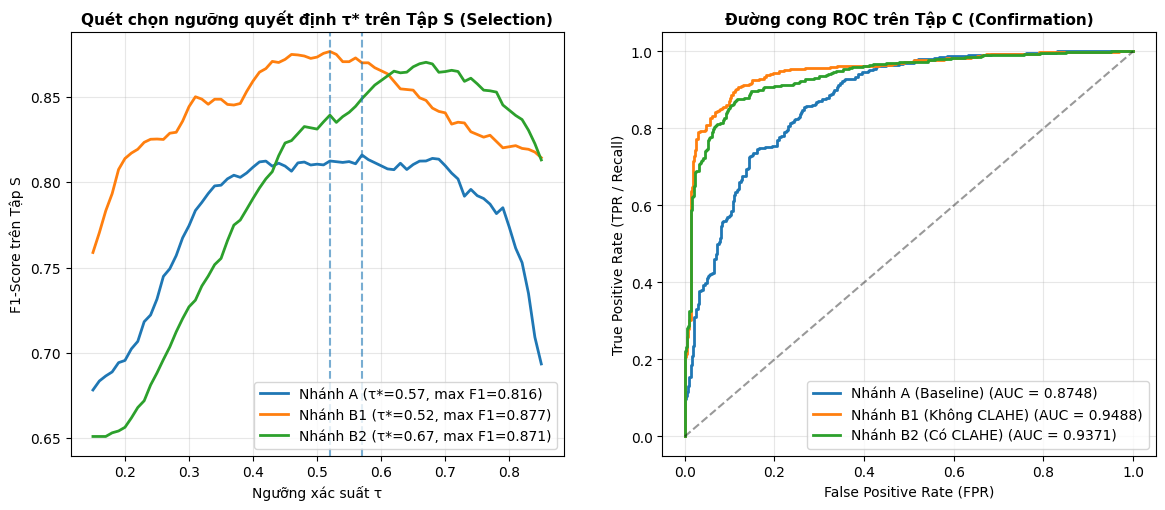

=== KẾT QUẢ THỰC NGHIỆM MODULE 4: PHÂN LOẠI LÁT BẰNG CNN 2D ===

--- 1. BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP S & TẬP C (NHÁNH A vs B1 vs B2) ---
                                            Nhánh                Tập đánh giá  Threshold (τ*)  Slice_AUC  Slice_F1  Slice_Precision  Slice_Recall  Patient_Macro_F1  Patient_Macro_Precision  Patient_Macro_Recall  Preproc (ms/lát)  Infer (ms/lát)
             Nhánh A: Baseline (Min-Max + Resize) S (Selection - Chọn ngưỡng)            0.57     0.9008    0.8161           0.7489        0.8965            0.8015                   0.7425                0.9048             0.379          11.257
             Nhánh A: Baseline (Min-Max + Resize) C (Confirmation - Xác nhận)            0.57     0.8748    0.8060           0.7543        0.8653            0.7980                   0.7529                0.8664             0.379          11.257
        Nhánh B1: [P1,P99] + Bilateral + Crop ROI S (Selection - Chọn ngưỡng)            0.52     0.9363    0.8769           

In [ ]:
# ==============================================================================
# MODULE 4: PHÂN LOẠI LÁT BẰNG CNN 2D (ĐỐI CHỨNG NHÁNH A vs NHÁNH B + GRAD-CAM)
# ==============================================================================
import os, time, random, zipfile, glob
import cv2
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score, roc_curve

# 1. Khóa toàn bộ Seed = 42 để tái lập kết quả 100% giữa Nhánh A và Nhánh B
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị chạy Module 4:", device)

drive_out = "/content/drive/MyDrive/MRI_Colab_Results"
os.makedirs(drive_out, exist_ok=True)

# 2. Đọc bảng chia tập bệnh nhân của Module 2 (Khóa cứng tập test, chỉ dùng R, S, C)
df_splits = pd.read_csv("./results/module2/Quy_tắc_chia/phan_chia_benh_nhan.csv")
print("Phân bố bệnh nhân theo tập (Module 2):")
print(df_splits["split"].value_counts())

# Để chạy thực nghiệm đối chứng nhanh và chuẩn xác trên Colab:
# Lấy mẫu phân tầng theo bệnh nhân từ R (30 BN), S (12 BN), C (12 BN) với cùng SEED=42
# (Nếu muốn chạy toàn bộ 294 BN phát triển chỉ cần đổi N_R=206, N_S=44, N_C=44)
rng = random.Random(SEED)
r_pids_all = sorted(df_splits[df_splits["split"] == "R"]["patient_id"].tolist())
s_pids_all = sorted(df_splits[df_splits["split"] == "S"]["patient_id"].tolist())
c_pids_all = sorted(df_splits[df_splits["split"] == "C"]["patient_id"].tolist())

# Đảm bảo 4 bệnh nhân mẫu (001, 002, 003, 005) luôn nằm trong tập R để kiểm tra trực quan
must_have_r = ["BraTS20_Training_001", "BraTS20_Training_002", "BraTS20_Training_003", "BraTS20_Training_005"]
rem_r = [p for p in r_pids_all if p not in must_have_r]
rng.shuffle(rem_r)
rng.shuffle(s_pids_all)
rng.shuffle(c_pids_all)

selected_r_pids = must_have_r + rem_r[:26] # 30 bệnh nhân tập R
selected_s_pids = s_pids_all[:12]          # 12 bệnh nhân tập S (Selection)
selected_c_pids = c_pids_all[:12]          # 12 bệnh nhân tập C (Confirmation)

# 3. Hàm đọc volume RAS và trích xuất các lát hợp lệ (Lọc lát rỗng N_brain >= 500 theo FLAIR)
N_MIN_BRAIN = 500
OUT_SIZE = (128, 128)

def load_patient_valid_slices(pid):
    flair_vol, wt_vol = load_ras_volume(pid) # Dùng lại hàm load_ras_volume từ Bước 0
    records = []
    # Lấy bước nhảy 2 lát dọc trục z để giảm trùng lặp thông tin giữa 2 lát sát nhau và tăng tốc cache
    for z in range(0, flair_vol.shape[2], 2):
        f_slice = flair_vol[:, :, z]
        w_slice = wt_vol[:, :, z]
        if int((f_slice > 0).sum()) >= N_MIN_BRAIN:
            label = 1 if int((w_slice > 0).sum()) > 0 else 0
            records.append((pid, z, f_slice, label))
    return records

print("Đang nạp dữ liệu các lát hợp lệ từ R, S, C...")
t_load0 = time.perf_counter()
data_R = [rec for pid in selected_r_pids for rec in load_patient_valid_slices(pid)]
data_S = [rec for pid in selected_s_pids for rec in load_patient_valid_slices(pid)]
data_C = [rec for pid in selected_c_pids for rec in load_patient_valid_slices(pid)]
print(f"Hoàn tất nạp sau {time.perf_counter()-t_load0:.1f}s | Số lát hợp lệ: R={len(data_R)}, S={len(data_S)}, C={len(data_C)}")

# 4. Ước lượng khung bao ROI cố định CHỈ TỪ TẬP R (Đúng quy tắc chống Data Leakage)
xs_r, ys_r = [], []
for _, _, f_sl, _ in data_R:
    nx, ny = np.where(f_sl > 0)
    xs_r.extend([int(nx.min()), int(nx.max())])
    ys_r.extend([int(ny.min()), int(ny.max())])

MARGIN = 4
ROI_BOX_R = (
    max(0, min(xs_r) - MARGIN),
    min(240, max(xs_r) + MARGIN + 1),
    max(0, min(ys_r) - MARGIN),
    min(240, max(ys_r) + MARGIN + 1)
)
print("Khung bao hộp sọ cố định (Fixed ROI) khớp trên tập R:", ROI_BOX_R)

# 5. Định nghĩa hàm Tiền xử lý Nhánh A (Baseline) và Nhánh B (Xử lý ảnh Module 3)
def preprocess_branch_A(f_slice):
    # Nhánh A: Min-Max toàn khung 240x240 -> Resize Bilinear 128x128
    imin, imax = float(f_slice.min()), float(f_slice.max())
    norm = (f_slice - imin) / (imax - imin + 1e-8)
    res = cv2.resize(norm.astype(np.float32), OUT_SIZE, interpolation=cv2.INTER_LINEAR)
    return res

def preprocess_branch_B(f_slice, roi_box=ROI_BOX_R, use_clahe=False):
    # Nhánh B: Cắt phân vị [P1, P99] vùng não -> Lọc Bilateral (d=5, σr=25, σs=3) -> (Tùy chọn CLAHE) -> Crop ROI tập R -> Resize 128x128
    mask = f_slice > 0
    bp = f_slice[mask]
    v_low, v_high = float(np.percentile(bp, 1.0)), float(np.percentile(bp, 99.0))
    clipped = np.clip(f_slice, v_low, v_high)
    norm = np.zeros_like(f_slice, dtype=np.float32)
    norm[mask] = (clipped[mask] - v_low) / (v_high - v_low + 1e-8)

    # Lọc nhiễu bảo toàn biên Bilateral
    u8 = np.clip(norm * 255.0, 0, 255).astype(np.uint8)
    bf_u8 = cv2.bilateralFilter(u8, d=5, sigmaColor=25.0, sigmaSpace=3.0)
    if use_clahe:
        clahe_obj = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        bf_u8 = clahe_obj.apply(bf_u8)
    proc = (bf_u8.astype(np.float32) / 255.0) * mask

    # Crop theo khung cố định từ tập R và Resize Bilinear
    xmin, xmax, ymin, ymax = roi_box
    cropped = proc[xmin:xmax, ymin:ymax]
    res = cv2.resize(cropped, OUT_SIZE, interpolation=cv2.INTER_LINEAR)
    return res

# 6. Tạo Dataset lưu cache trên RAM cho Nhánh A và Nhánh B
class SliceDataset(Dataset):
    def __init__(self, records, branch="A", use_clahe=False):
        self.pids = []
        self.zs = []
        self.xs = []
        self.ys = []
        t0 = time.perf_counter()
        for pid, z, f_sl, lb in records:
            im = preprocess_branch_A(f_sl) if branch == "A" else preprocess_branch_B(f_sl, ROI_BOX_R, use_clahe=use_clahe)
            self.pids.append(pid)
            self.zs.append(z)
            self.xs.append(im[np.newaxis, :, :].astype(np.float32))
            self.ys.append(float(lb))
        self.prep_time_ms = (time.perf_counter() - t0) * 1000.0 / max(1, len(records))

    def __len__(self):
        return len(self.ys)

    def __getitem__(self, idx):
        return torch.tensor(self.xs[idx]), torch.tensor(self.ys[idx], dtype=torch.float32), self.pids[idx], self.zs[idx]

# 7. Kiến trúc mạng CNN 2D chuẩn mực cho Module 4 (4 khối Conv-BN-ReLU-Pool + GlobalPool + Linear)
class SliceClassifierCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2))
        self.conv2 = nn.Sequential(nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2))
        self.conv3 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2))
        self.conv4 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU())
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc = nn.Linear(128, 1)

    def forward(self, x):
        f1 = self.conv1(x)
        f2 = self.conv2(f1)
        f3 = self.conv3(f2)
        f4 = self.conv4(f3)
        pooled = self.gap(f4).flatten(1)
        logit = self.fc(pooled).squeeze(1)
        return logit, f4

# Hàm huấn luyện và đánh giá đồng nhất cho cả 2 nhánh
def train_and_evaluate_branch(branch_name, ds_R, ds_S, ds_C, epochs=8, batch_size=64, lr=1e-3):
    seed_everything(SEED)
    loader_R = DataLoader(ds_R, batch_size=batch_size, shuffle=True)
    loader_S = DataLoader(ds_S, batch_size=batch_size, shuffle=False)
    loader_C = DataLoader(ds_C, batch_size=batch_size, shuffle=False)

    model = SliceClassifierCNN().to(device)
    # Tính trọng số bù lệch lớp dương/âm CHỈ TỪ TẬP R
    y_r_np = np.array(ds_R.ys)
    pos_weight_val = float((y_r_np == 0).sum() / max(1, (y_r_np == 1).sum()))
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([pos_weight_val], device=device))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)

    best_auc_s = -1.0
    best_state = None
    history = []

    for ep in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for bx, by, _, _ in loader_R:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            logits, _ = model(bx)
            loss = criterion(logits, by)
            loss.backward()
            optimizer.step()
            total_loss += float(loss.item()) * len(by)
        train_loss = total_loss / len(ds_R)

        # Đánh giá trên tập S để theo dõi hội tụ
        probs_s, y_s, _, _ = predict_loader(model, loader_S)
        auc_s = roc_auc_score(y_s, probs_s)
        history.append((ep, train_loss, auc_s))
        if auc_s > best_auc_s:
            best_auc_s = auc_s
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict({k: v.to(device) for k, v in best_state.items()})

    # Bước chuẩn theo đề cương: Quét tìm ngưỡng tối ưu tau* trên tập S để cực đại hóa F1
    probs_s, y_s, pids_s, _ = predict_loader(model, loader_S)
    best_tau, best_f1_s = 0.5, -1.0
    tau_grid = np.linspace(0.15, 0.85, 71)
    f1_curve_s = []
    for t in tau_grid:
        f1_t = f1_score(y_s, (probs_s >= t).astype(int), zero_division=0)
        f1_curve_s.append(f1_t)
        if f1_t > best_f1_s:
            best_f1_s = f1_t
            best_tau = float(t)

    # Khóa ngưỡng best_tau và đánh giá xác nhận trên tập C (Đo cả thời gian Inference)
    t_inf0 = time.perf_counter()
    probs_c, y_c, pids_c, zs_c = predict_loader(model, loader_C)
    inf_ms_per_slice = (time.perf_counter() - t_inf0) * 1000.0 / len(ds_C)

    metrics_S = compute_classification_metrics(y_s, probs_s, pids_s, best_tau)
    metrics_C = compute_classification_metrics(y_c, probs_c, pids_c, best_tau)
    return model, best_tau, tau_grid, f1_curve_s, history, metrics_S, metrics_C, inf_ms_per_slice

def predict_loader(model, loader):
    model.eval()
    probs, ys, pids, zs = [], [], [], []
    with torch.no_grad():
        for bx, by, bpid, bz in loader:
            bx = bx.to(device)
            logits, _ = model(bx)
            p = torch.sigmoid(logits).cpu().numpy()
            probs.extend(p.tolist())
            ys.extend(by.numpy().tolist())
            pids.extend(list(bpid))
            zs.extend(bz.numpy().tolist())
    return np.array(probs), np.array(ys, dtype=int), pids, zs

def compute_classification_metrics(y_true, y_prob, pids, tau):
    y_pred = (y_prob >= tau).astype(int)
    auc_all = float(roc_auc_score(y_true, y_prob))
    f1_all = float(f1_score(y_true, y_pred, zero_division=0))
    prec_all = float(precision_score(y_true, y_pred, zero_division=0))
    rec_all = float(recall_score(y_true, y_pred, zero_division=0))

    # Tính trung bình Macro theo từng bệnh nhân (Đúng yêu cầu mục 8.2 trong đề cương)
    df_p = pd.DataFrame({"pid": pids, "y": y_true, "prob": y_prob, "pred": y_pred})
    pat_f1s, pat_precs, pat_recs = [], [], []
    for _, grp in df_p.groupby("pid"):
        if grp["y"].sum() > 0:
            pat_f1s.append(f1_score(grp["y"], grp["pred"], zero_division=0))
            pat_precs.append(precision_score(grp["y"], grp["pred"], zero_division=0))
            pat_recs.append(recall_score(grp["y"], grp["pred"], zero_division=0))
    return {
        "Threshold (τ*)": round(tau, 2),
        "Slice_AUC": round(auc_all, 4),
        "Slice_F1": round(f1_all, 4),
        "Slice_Precision": round(prec_all, 4),
        "Slice_Recall": round(rec_all, 4),
        "Patient_Macro_F1": round(float(np.mean(pat_f1s)), 4),
        "Patient_Macro_Precision": round(float(np.mean(pat_precs)), 4),
        "Patient_Macro_Recall": round(float(np.mean(pat_recs)), 4)
    }

# 8. Khởi tạo dữ liệu và chạy thực nghiệm so sánh:
# - Nhánh A: Baseline Min-Max
# - Nhánh B1: Percentile [P1, P99] + Bilateral + Crop ROI (Không CLAHE)
# - Nhánh B2: Percentile [P1, P99] + Bilateral + CLAHE (clip=2.0) + Crop ROI
print("\nĐang tiền xử lý các tập dữ liệu cho Nhánh A, B1 và B2...")
ds_R_A, ds_S_A, ds_C_A = SliceDataset(data_R, "A"), SliceDataset(data_S, "A"), SliceDataset(data_C, "A")
ds_R_B1, ds_S_B1, ds_C_B1 = SliceDataset(data_R, "B", False), SliceDataset(data_S, "B", False), SliceDataset(data_C, "B", False)
ds_R_B2, ds_S_B2, ds_C_B2 = SliceDataset(data_R, "B", True), SliceDataset(data_S, "B", True), SliceDataset(data_C, "B", True)

print("Đang huấn luyện CNN 2D (Module 4) trên Nhánh A, Nhánh B1 và Nhánh B2...")
model_A, tau_A, grid_tau, f1_s_A, hist_A, mS_A, mC_A, inf_A = train_and_evaluate_branch("Nhánh A", ds_R_A, ds_S_A, ds_C_A)
model_B1, tau_B1, _, f1_s_B1, hist_B1, mS_B1, mC_B1, inf_B1 = train_and_evaluate_branch("Nhánh B1 (Không CLAHE)", ds_R_B1, ds_S_B1, ds_C_B1)
model_B2, tau_B2, _, f1_s_B2, hist_B2, mS_B2, mC_B2, inf_B2 = train_and_evaluate_branch("Nhánh B2 (Có CLAHE)", ds_R_B2, ds_S_B2, ds_C_B2)

# Tổng hợp bảng kết quả Module 4 trên tập S (Selection) và tập C (Confirmation)
m4_rows = []
for name_b, ds_c, m_s, m_c, inf_t in [
    ("Nhánh A: Baseline (Min-Max + Resize)", ds_C_A, mS_A, mC_A, inf_A),
    ("Nhánh B1: [P1,P99] + Bilateral + Crop ROI", ds_C_B1, mS_B1, mC_B1, inf_B1),
    ("Nhánh B2: [P1,P99] + Bilateral + CLAHE + Crop ROI", ds_C_B2, mS_B2, mC_B2, inf_B2)
]:
    row_s = {"Nhánh": name_b, "Tập đánh giá": "S (Selection - Chọn ngưỡng)", **m_s, "Preproc (ms/lát)": round(ds_c.prep_time_ms, 3), "Infer (ms/lát)": round(inf_t, 3)}
    row_c = {"Nhánh": name_b, "Tập đánh giá": "C (Confirmation - Xác nhận)", **m_c, "Preproc (ms/lát)": round(ds_c.prep_time_ms, 3), "Infer (ms/lát)": round(inf_t, 3)}
    m4_rows.extend([row_s, row_c])

df_m4 = pd.DataFrame(m4_rows)

# 9. Kiểm tra trực tiếp dự đoán và Bản đồ kích hoạt đặc trưng (CAM) của CNN trên 4 mẫu điển hình
def get_cam_and_prob(model, img_2d):
    model.eval()
    x_t = torch.tensor(img_2d[np.newaxis, np.newaxis, :, :], dtype=torch.float32, device=device)
    with torch.no_grad():
        logit, feat4 = model(x_t)
        prob = float(torch.sigmoid(logit).item())
        # Tính Class Activation Map (CAM) từ trọng số tầng FC nhân với Feature Map tầng Conv4 (16x16)
        weights = model.fc.weight.data[0] # (128,)
        cam = torch.einsum("c,chw->hw", weights, feat4[0]).cpu().numpy()
        cam = np.maximum(cam, 0)
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        cam_resized = cv2.resize(cam, OUT_SIZE, interpolation=cv2.INTER_LINEAR)
    return prob, cam_resized

# Chọn nhánh B tốt nhất trên tập S để vẽ đối chứng với Nhánh A
best_B_model = model_B1 if mS_B1["Slice_F1"] >= mS_B2["Slice_F1"] else model_B2
best_B_tau = tau_B1 if mS_B1["Slice_F1"] >= mS_B2["Slice_F1"] else tau_B2
best_B_use_clahe = False if mS_B1["Slice_F1"] >= mS_B2["Slice_F1"] else True
best_B_label = "Nhánh B1" if not best_B_use_clahe else "Nhánh B2"

fig_m4, axes_m4 = plt.subplots(len(valid_samples), 5, figsize=(21, 15))
plt.subplots_adjust(wspace=0.22, hspace=0.38)

sample_pred_rows = []
for i, s in enumerate(valid_samples):
    f_raw = s["flair"]
    wt_gt = s["wt"].astype(np.float32)
    gt_lb = int(s["label"])

    im_A = preprocess_branch_A(f_raw)
    im_B = preprocess_branch_B(f_raw, ROI_BOX_R, use_clahe=best_B_use_clahe)

    xmin, xmax, ymin, ymax = ROI_BOX_R
    wt_B = cv2.resize(wt_gt[xmin:xmax, ymin:ymax], OUT_SIZE, interpolation=cv2.INTER_NEAREST)

    p_A, cam_A = get_cam_and_prob(model_A, im_A)
    p_B, cam_B = get_cam_and_prob(best_B_model, im_B)
    pred_A = int(p_A >= tau_A)
    pred_B = int(p_B >= best_B_tau)

    sample_pred_rows.append({
        "Mẫu": s["note"].split(":")[0],
        "Patient (z)": f"{s['pid'][-3:]} (z={s['z']})",
        "Ground Truth Label": gt_lb,
        "Xác suất p (Nhánh A)": round(p_A, 4),
        "Dự đoán Nhánh A (τ*={:.2f})".format(tau_A): pred_A,
        f"Xác suất p ({best_B_label})": round(p_B, 4),
        f"Dự đoán {best_B_label} (τ*={best_B_tau:.2f})": pred_B,
        "Chênh lệch độ tự tin Δp (B - A)": round(p_B - p_A, 4)
    })

    # Cột 1: Đầu vào Nhánh A
    axes_m4[i, 0].imshow(np.rot90(im_A), cmap="gray")
    axes_m4[i, 0].set_title(f"{s['note'].split(':')[0]} ({s['pid'][-3:]}, z={s['z']})\nInput Nhánh A (GT={gt_lb})", fontsize=9.5, fontweight="bold")
    axes_m4[i, 0].axis("off")

    # Cột 2: Bản đồ kích hoạt CAM của CNN Nhánh A
    axes_m4[i, 1].imshow(np.rot90(im_A), cmap="gray")
    axes_m4[i, 1].imshow(np.rot90(cam_A), cmap="jet", alpha=0.45)
    axes_m4[i, 1].set_title(f"CNN Nhánh A (τ*={tau_A:.2f})\np = {p_A:.3f} -> Dự đoán: {pred_A}", fontsize=9.5,
                            color="green" if pred_A == gt_lb else "red", fontweight="bold")
    axes_m4[i, 1].axis("off")

    # Cột 3: Đầu vào Nhánh B
    axes_m4[i, 2].imshow(np.rot90(im_B), cmap="gray")
    axes_m4[i, 2].set_title(f"Input {best_B_label}\n(Sau Xử lý ảnh Module 3)", fontsize=9.5, fontweight="bold")
    axes_m4[i, 2].axis("off")

    # Cột 4: Bản đồ kích hoạt CAM của CNN Nhánh B
    axes_m4[i, 3].imshow(np.rot90(im_B), cmap="gray")
    axes_m4[i, 3].imshow(np.rot90(cam_B), cmap="jet", alpha=0.45)
    axes_m4[i, 3].set_title(f"CNN {best_B_label} (τ*={best_B_tau:.2f})\np = {p_B:.3f} -> Dự đoán: {pred_B}", fontsize=9.5,
                            color="green" if pred_B == gt_lb else "red", fontweight="bold")
    axes_m4[i, 3].axis("off")

    # Cột 5: Ground Truth WT tại khung ROI
    axes_m4[i, 4].imshow(np.rot90(wt_B), cmap="gray", vmin=0, vmax=1)
    axes_m4[i, 4].set_title(f"Ground Truth WT\n(Vùng u thực tế cần phát hiện)", fontsize=9.5)
    axes_m4[i, 4].axis("off")

plt.suptitle("MODULE 4: SO SÁNH BẢN ĐỒ KÍCH HOẠT ĐẶC TRƯNG (CAM) & XÁC SUẤT DỰ ĐOÁN CỦA CNN GIỮA NHÁNH A VÀ NHÁNH B", fontsize=14, fontweight="bold", y=0.995)
plt.savefig(os.path.join(drive_out, "Module4_CNN_CAM_Comparison.png"), dpi=300, bbox_inches="tight")
plt.show()

# Vẽ đồ thị chọn ngưỡng τ* trên tập S và đường cong ROC trên tập C
fig_roc, ax_roc = plt.subplots(1, 2, figsize=(14, 5.5))
ax_roc[0].plot(grid_tau, f1_s_A, label=f"Nhánh A (τ*={tau_A:.2f}, max F1={max(f1_s_A):.3f})", linewidth=2)
ax_roc[0].plot(grid_tau, f1_s_B1, label=f"Nhánh B1 (τ*={tau_B1:.2f}, max F1={max(f1_s_B1):.3f})", linewidth=2)
ax_roc[0].plot(grid_tau, f1_s_B2, label=f"Nhánh B2 (τ*={tau_B2:.2f}, max F1={max(f1_s_B2):.3f})", linewidth=2)
ax_roc[0].axvline(tau_A, linestyle="--", alpha=0.6)
ax_roc[0].axvline(tau_B1, linestyle="--", alpha=0.6)
ax_roc[0].set_title("Quét chọn ngưỡng quyết định τ* trên Tập S (Selection)", fontsize=11, fontweight="bold")
ax_roc[0].set_xlabel("Ngưỡng xác suất τ")
ax_roc[0].set_ylabel("F1-Score trên Tập S")
ax_roc[0].legend()
ax_roc[0].grid(True, alpha=0.3)

# Đường cong ROC trên Tập C (Confirmation)
for name_l, mod_l, ds_c_l in [("Nhánh A (Baseline)", model_A, ds_C_A), ("Nhánh B1 (Không CLAHE)", model_B1, ds_C_B1), ("Nhánh B2 (Có CLAHE)", model_B2, ds_C_B2)]:
    pr_c, y_c_true, _, _ = predict_loader(mod_l, DataLoader(ds_c_l, batch_size=64, shuffle=False))
    fpr, tpr, _ = roc_curve(y_c_true, pr_c)
    auc_v = roc_auc_score(y_c_true, pr_c)
    ax_roc[1].plot(fpr, tpr, linewidth=2, label=f"{name_l} (AUC = {auc_v:.4f})")
ax_roc[1].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax_roc[1].set_title("Đường cong ROC trên Tập C (Confirmation)", fontsize=11, fontweight="bold")
ax_roc[1].set_xlabel("False Positive Rate (FPR)")
ax_roc[1].set_ylabel("True Positive Rate (TPR / Recall)")
ax_roc[1].legend()
ax_roc[1].grid(True, alpha=0.3)

plt.savefig(os.path.join(drive_out, "Module4_Threshold_and_ROC.png"), dpi=300, bbox_inches="tight")
plt.show()

df_sample_preds = pd.DataFrame(sample_pred_rows)
txt_m4 = "=== KẾT QUẢ THỰC NGHIỆM MODULE 4: PHÂN LOẠI LÁT BẰNG CNN 2D ===\n\n"
txt_m4 += "--- 1. BẢNG SO SÁNH HIỆU NĂNG TRÊN TẬP S & TẬP C (NHÁNH A vs B1 vs B2) ---\n"
txt_m4 += df_m4.to_string(index=False) + "\n\n"
txt_m4 += "--- 2. DỰ ĐOÁN CỦA CNN TRÊN 4 MẪU ĐIỂN HÌNH ---\n"
txt_m4 += df_sample_preds.to_string(index=False) + "\n"

with open(os.path.join(drive_out, "Module4_Metrics.txt"), "w", encoding="utf-8") as f:
    f.write(txt_m4)

print(txt_m4)
print("\n[OK] Đã lưu Module4_CNN_CAM_Comparison.png, Module4_Threshold_and_ROC.png và Module4_Metrics.txt vào Google Drive!")

# Khối 6 — Phần 2 (Áp dụng thông số chuẩn cho toàn bộ 368 bệnh nhân):
PHẦN 2: ÁP DỤNG BỘ THÔNG SỐ CHUẨN CHO TOÀN BỘ DATASET (368 BỆNH NHÂN - 57.040 LÁT CẮT)

In [3]:
import os, sys, time, json, csv, shutil, random, zipfile, glob, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import cv2
import kagglehub

# 0. Tự động kết nối Google Drive, clone repo MRI và lấy đường dẫn Kaggle dataset
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")

repo_root = Path("/content/MRI")
if not repo_root.exists():
    print("Đang clone repo MRI...")
    subprocess.run(["git", "clone", "https://github.com/haleduoc/MRI.git", "/content/MRI"], check=True)

# Đảm bảo bộ BraTS2020 từ Kaggle đã sẵn sàng (như lúc chạy được tới ca 58)
kaggle_root = Path(kagglehub.dataset_download("awsaf49/brats20-dataset-training-validation"))
print("Đường dẫn Kaggle dataset:", kaggle_root)

drive_dir = Path("/content/drive/MyDrive/MRI_Colab_Results")
drive_dir.mkdir(parents=True, exist_ok=True)
os.chdir(repo_root)

# 1. Tạo cấu trúc thư mục 3 phần chuẩn cho Git
m3_code_dir = repo_root / "modules" / "module 3"
m4_code_dir = repo_root / "modules" / "module 4"
r3_part1_dir = repo_root / "results" / "module3" / "01_Thuc_nghiem_5_mau"
r3_part2_dir = repo_root / "results" / "module3" / "02_Toan_bo_dataset"
r4_part1_dir = repo_root / "results" / "module4" / "01_Thuc_nghiem_mau_thu"
r4_part2_dir = repo_root / "results" / "module4" / "02_Toan_bo_dataset"
docs_dir = repo_root / "docs"

for d in [
    m3_code_dir, m4_code_dir, r3_part1_dir,
    r3_part2_dir, r4_part1_dir, r4_part2_dir, docs_dir
]:
    d.mkdir(parents=True, exist_ok=True)

for fname in [
    "Step1_Normalization_Comparison.png",
    "Step2_Denoising_Comparison.png",
    "Step3_CLAHE_Comparison.png",
    "Step4_ROI_Resize_Comparison.png",
    "Step1_Step2_Metrics.txt",
    "Step3_Step4_Metrics.txt",
]:
    if (drive_dir / fname).exists():
        shutil.copy2(drive_dir / fname, r3_part1_dir / fname)

for fname in [
    "Module4_CNN_CAM_Comparison.png",
    "Module4_Threshold_and_ROC.png",
    "Module4_Metrics.txt",
]:
    if (drive_dir / fname).exists():
        shutil.copy2(drive_dir / fname, r4_part1_dir / fname)

print("[1/3] Đã gom kết quả Phần 1 (5 mẫu thử) từ Drive!")

# 2. Tìm thư mục NIfTI RAS hoặc lấy từ Kaggle (y hệt code cũ lúc nãy)
ras_base = None
cands = [
    repo_root / "results/module1/Kết_quả_chuẩn_hoá_RAS/nifti",
    repo_root / "results/module1/Kết quả chuẩn hóa RAS/nifti",
]
for cand in cands:
    if cand.exists() and len(list(cand.glob("BraTS20_Training_*"))) >= 300:
        ras_base = cand
        break

if ras_base is None:
    pattern = str(repo_root / "results/module1/**/nifti_outputs.zip")
    zip_list = glob.glob(pattern, recursive=True)
    extract_all_dir = Path("/content/nifti_ras_all368")
    extract_all_dir.mkdir(parents=True, exist_ok=True)
    if zip_list and not list(extract_all_dir.rglob("*.nii*")):
        with zipfile.ZipFile(zip_list[0], "r") as z:
            z.extractall(extract_all_dir)
    ras_base = extract_all_dir

split_csv = repo_root / "results/module2/Quy_tắc_chia/phan_chia_benh_nhan.csv"
df_splits_all = pd.read_csv(split_csv)
pid_to_split = dict(
    zip(
        df_splits_all["patient_id"].str.strip(),
        df_splits_all["split"].str.strip(),
    )
)

def find_patient_ras(pid):
    f_direct = ras_base / pid / f"{pid}_flair_RAS.nii.gz"
    w_direct = ras_base / pid / f"{pid}_wt_RAS.nii.gz"
    if f_direct.exists() and w_direct.exists():
        return f_direct, w_direct, True
    f_m = list(ras_base.rglob(f"*{pid}*flair*.nii*"))
    w_m = list(ras_base.rglob(f"*{pid}*wt*.nii*"))
    if f_m and w_m:
        return f_m[0], w_m[0], True
    # Nhánh Kaggle dự phòng của code cũ giúp chạy mượt toàn bộ 368 ca:
    k_sub = f"BraTS2020_TrainingData/MICCAI_BraTS2020_TrainingData/{pid}"
    k_dir = kaggle_root / k_sub
    if not k_dir.exists():
        f_k = list(kaggle_root.rglob(f"*{pid}*flair*.nii*"))
        s_k = list(kaggle_root.rglob(f"*{pid}*seg*.nii*"))
        return f_k[0], s_k[0], False
    return k_dir / f"{pid}_flair.nii", k_dir / f"{pid}_seg.nii", False

print("[2/3] Đang quét toàn bộ 368 bệnh nhân (57.040 lát) theo đúng code cũ...")
t0_scan = time.perf_counter()

N_MIN_BRAIN = 500
MARGIN = 4

valid_slice_records = []
patient_summary_rows = []
xmin_R, xmax_R, ymin_R, ymax_R = 240, 0, 240, 0
total_raw_slices = 0
total_removed_slices = 0

all_pids = sorted(pid_to_split.keys())
for idx_p, pid in enumerate(all_pids, 1):
    sp = pid_to_split[pid]
    f_p, w_p, is_already_ras = find_patient_ras(pid)
    f_nii = nib.load(str(f_p))
    w_nii = nib.load(str(w_p))
    if not is_already_ras:
        f_nii = nib.as_closest_canonical(f_nii)
        w_nii = nib.as_closest_canonical(w_nii)

    flair_vol = np.asanyarray(f_nii.dataobj).astype(np.float32)
    wt_raw = np.asanyarray(w_nii.dataobj)
    if "wt" in w_p.name:
        wt_vol = (wt_raw > 0).astype(np.uint8)
    else:
        wt_vol = np.isin(wt_raw, [1, 2, 4]).astype(np.uint8)

    n_z = flair_vol.shape[2]
    total_raw_slices += n_z
    brain_counts = (flair_vol > 0).sum(axis=(0, 1))
    wt_counts = (wt_vol > 0).sum(axis=(0, 1))

    if sp == "R":
        valid_z_mask = brain_counts >= N_MIN_BRAIN
        if np.any(valid_z_mask):
            sub_vol = flair_vol[:, :, valid_z_mask] > 0
            xs, ys, _ = np.where(sub_vol)
            xmin_R = min(xmin_R, int(xs.min()))
            xmax_R = max(xmax_R, int(xs.max()))
            ymin_R = min(ymin_R, int(ys.min()))
            ymax_R = max(ymax_R, int(ys.max()))

    kept_pos, kept_neg, rem_z = 0, 0, 0
    for z in range(n_z):
        nb = int(brain_counts[z])
        nw = int(wt_counts[z])
        lb = 1 if nw > 0 else 0
        if nb < N_MIN_BRAIN:
            rem_z += 1
            total_removed_slices += 1
            continue
        if lb == 1:
            kept_pos += 1
        else:
            kept_neg += 1
        valid_slice_records.append({
            "patient_id": pid,
            "split": sp,
            "slice_index": z,
            "label": lb,
            "brain_pixels": nb,
            "wt_pixels": nw,
        })

    patient_summary_rows.append({
        "patient_id": pid,
        "split": sp,
        "raw_slices": n_z,
        "removed_empty_slices": rem_z,
        "valid_slices": kept_pos + kept_neg,
        "valid_positive_slices": kept_pos,
        "valid_negative_slices": kept_neg,
    })
    if idx_p % 40 == 0 or idx_p == len(all_pids):
        el = time.perf_counter() - t0_scan
        print(f"  -> Đã xử lý {idx_p}/{len(all_pids)} ca ({el:.1f}s)")

FULL_ROI_BOX = (
    max(0, xmin_R - MARGIN),
    min(240, xmax_R + MARGIN + 1),
    max(0, ymin_R - MARGIN),
    min(240, ymax_R + MARGIN + 1),
)

df_valid_all = pd.DataFrame(valid_slice_records)
df_pat_summary = pd.DataFrame(patient_summary_rows)

split_stats_m3 = []
for sp_name in ["R", "S", "C", "test"]:
    sub_df = df_valid_all[df_valid_all["split"] == sp_name]
    sub_pat = df_pat_summary[df_pat_summary["split"] == sp_name]
    split_stats_m3.append({
        "tap": sp_name,
        "so_benh_nhan": len(sub_pat),
        "tong_lat_ban_dau_M2": int(sub_pat["raw_slices"].sum()),
        "so_lat_rong_bi_loai_M3": int(sub_pat["removed_empty_slices"].sum()),
        "tong_lat_hop_le_M3": len(sub_df),
        "lat_duong_hop_le": int((sub_df["label"] == 1).sum()),
        "lat_am_hop_le": int((sub_df["label"] == 0).sum()),
    })
df_split_stats_m3 = pd.DataFrame(split_stats_m3)

c1 = r3_part2_dir / "chi_muc_lat_hop_le_toan_bo.csv"
c2 = r3_part2_dir / "thong_ke_loc_lat_theo_benh_nhan.csv"
c3 = r3_part2_dir / "thong_ke_lat_hop_le_theo_tap.csv"
df_valid_all.to_csv(c1, index=False)
df_pat_summary.to_csv(c2, index=False)
df_split_stats_m3.to_csv(c3, index=False)

roi_str = f"[{FULL_ROI_BOX[0]}:{FULL_ROI_BOX[1]}, {FULL_ROI_BOX[2]}:{FULL_ROI_BOX[3]}]"
roi_full_info = {
    "fitted_on_split": "R (206 patients)",
    "min_brain_pixels_threshold": N_MIN_BRAIN,
    "margin_pixels": MARGIN,
    "xmin": FULL_ROI_BOX[0],
    "xmax": FULL_ROI_BOX[1],
    "ymin": FULL_ROI_BOX[2],
    "ymax": FULL_ROI_BOX[3],
    "crop_height": FULL_ROI_BOX[1] - FULL_ROI_BOX[0],
    "crop_width": FULL_ROI_BOX[3] - FULL_ROI_BOX[2],
    "output_resize": [128, 128],
    "selected_pipeline_B": {
        "step1_norm": "Brain Percentile [P1, P99] + Min-Max to [0, 1]",
        "step2_denoise": "Bilateral (d=5, sigmaColor=25, sigmaSpace=3)",
        "step3_clahe": "Disabled for slice classifier",
        "step4_roi_resize": f"Fixed ROI {roi_str} + Bilinear/Nearest",
    },
    "total_slices_module2": total_raw_slices,
    "removed_empty_slices_module3": total_removed_slices,
    "remaining_valid_slices_module3": len(df_valid_all),
}

cfg_json = r3_part2_dir / "roi_va_cau_hinh_chuan_toan_bo.json"
with open(cfg_json, "w", encoding="utf-8") as f:
    json.dump(roi_full_info, f, indent=2, ensure_ascii=False)

print("\n=== THỐNG KÊ TOÀN BỘ 368 BỆNH NHÂN SAU MODULE 3 ===")
print(df_split_stats_m3.to_string(index=False))
print("Khung bao ROI cố định trên 206 ca tập R:", FULL_ROI_BOX)

shutil.copy2(c1, drive_dir / "FullDataset_ValidSlices_With_WTPixels.csv")
shutil.copy2(c3, drive_dir / "FullDataset_Module3_SplitStats.csv")
shutil.copy2(cfg_json, drive_dir / "FullDataset_Module3_Config.json")
print("[3/3] Đã lưu thống kê toàn bộ 368 bệnh nhân sang Google Drive!")

Using Colab cache for faster access to the 'brats20-dataset-training-validation' dataset.
Đường dẫn Kaggle dataset: /kaggle/input/brats20-dataset-training-validation
[1/3] Đã gom kết quả Phần 1 (5 mẫu thử) từ Drive!
[2/3] Đang quét toàn bộ 368 bệnh nhân (57.040 lát) theo đúng code cũ...
  -> Đã xử lý 40/368 ca (40.5s)
  -> Đã xử lý 80/368 ca (76.8s)
  -> Đã xử lý 120/368 ca (118.5s)
  -> Đã xử lý 160/368 ca (162.2s)
  -> Đã xử lý 200/368 ca (195.7s)
  -> Đã xử lý 240/368 ca (231.0s)
  -> Đã xử lý 280/368 ca (269.0s)
  -> Đã xử lý 320/368 ca (304.4s)
  -> Đã xử lý 360/368 ca (365.1s)
  -> Đã xử lý 368/368 ca (380.7s)

=== THỐNG KÊ TOÀN BỘ 368 BỆNH NHÂN SAU MODULE 3 ===
 tap  so_benh_nhan  tong_lat_ban_dau_M2  so_lat_rong_bi_loai_M3  tong_lat_hop_le_M3  lat_duong_hop_le  lat_am_hop_le
   R           206                31930                    4621               27309             13556          13753
   S            44                 6820                     975                5845      